In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:

from google.colab import drive
drive.mount('/content/gdrive')

from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

print("Processed directory exists:", BASE_DIR.exists())

if BASE_DIR.exists():
    print("\nRelevant files:")
    for name in [
        "lucknow_district_analytical.gpkg",
        "lucknow_district_boundaries.gpkg",
        "lucknow_rural_healthcare_join.gpkg",
        "lucknow_hospital_master_cleaned.csv",
        "village_data_lucknow.csv",
        "town_data_lucknow.csv",
    ]:
        path = BASE_DIR / name
        print(f"{name}: {'FOUND' if path.exists() else 'NOT FOUND'}")


Mounted at /content/gdrive
Processed directory exists: True

Relevant files:
lucknow_district_analytical.gpkg: FOUND
lucknow_district_boundaries.gpkg: FOUND
lucknow_rural_healthcare_join.gpkg: FOUND
lucknow_hospital_master_cleaned.csv: FOUND
village_data_lucknow.csv: FOUND
town_data_lucknow.csv: FOUND


In [ ]:

import geopandas as gpd
import pandas as pd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

gpkg_files = {
    "Analytical geography": BASE_DIR / "lucknow_district_analytical.gpkg",
    "Original boundary source": BASE_DIR / "lucknow_district_boundaries.gpkg",
    "Healthcare join": BASE_DIR / "lucknow_rural_healthcare_join.gpkg",
}

for label, path in gpkg_files.items():
    print("\n" + "=" * 80)
    print(label)
    print("File:", path.name)

    try:
        layers = gpd.list_layers(path)
        print("\nAvailable layers:")
        print(layers.to_string(index=False))

        for layer_name in layers["name"]:
            gdf = gpd.read_file(path, layer=layer_name)

            print(f"\n--- Layer: {layer_name} ---")
            print("Rows:", len(gdf))
            print("Columns:", len(gdf.columns))
            print("CRS:", gdf.crs)
            print("Geometry types:", gdf.geometry.geom_type.value_counts().to_dict())

            print("Column names:")
            print(gdf.columns.tolist())

    except Exception as e:
        print("ERROR:", repr(e))



Analytical geography
File: lucknow_district_analytical.gpkg


/usr/local/lib/python3.13/dist-packages/pyogrio/core.py:169: RuntimeWarning: Table/view villages_towns_2011_corrected is referenced in gpkg_contents, but does not exist
  return ogr_list_layers(get_vsi_path_or_buffer(path_or_buffer))
/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Table/view villages_towns_2011_corrected is referenced in gpkg_contents, but does not exist
  return ogr_read(



Available layers:
                  name geometry_type
   villages_towns_2011       Polygon
          tehsils_2011  MultiPolygon
district_boundary_2011       Polygon

--- Layer: villages_towns_2011 ---
Rows: 819
Columns: 13
CRS: GEOGCS["WGS 84 (CRS84)",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Longitude",EAST],AXIS["Latitude",NORTH],AUTHORITY["OGC","CRS84"]]
Geometry types: {'Polygon': 819}
Column names:
['pc11_s_id', 'pc11_d_id', 'pc11_sd_id', 'tehsil_name', 'pc11_tv_id', 'tv_name', 'tv_name_dir', 'is_town', 'pop2011_villagept', 'gp_code', 'gp_name', 'area_km2', 'geometry']

--- Layer: tehsils_2011 ---
Rows: 4
Columns: 10
CRS: GEOGCS["WGS 84 (CRS84)",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT

/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Table/view villages_towns_2011_corrected is referenced in gpkg_contents, but does not exist
  return ogr_read(
/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Table/view villages_towns_2011_corrected is referenced in gpkg_contents, but does not exist
  return ogr_read(



Available layers:
                     name geometry_type
             tehsils_2011  MultiPolygon
villages_towns_shrug_pc11       Polygon
village_points_census2011         Point
   villages_lgd_blocks_gp  MultiPolygon

--- Layer: tehsils_2011 ---
Rows: 4
Columns: 10
CRS: GEOGCS["WGS 84 (CRS84)",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Longitude",EAST],AXIS["Latitude",NORTH],AUTHORITY["OGC","CRS84"]]
Geometry types: {'MultiPolygon': 4}
Column names:
['stcode11', 'dtcode11', 'sdtcode11', 'sdtname', 'Subdt_LGD', 'Dist_LGD', 'pop2011', 'tehsil_name', 'area_km2', 'geometry']

--- Layer: villages_towns_shrug_pc11 ---
Rows: 819
Columns: 13
CRS: GEOGCS["WGS 84 (CRS84)",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8

In [ ]:

import geopandas as gpd
import pandas as pd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

join_path = BASE_DIR / 'lucknow_rural_healthcare_join.gpkg'
village_path = BASE_DIR / 'village_data_lucknow.csv'
town_path = BASE_DIR / 'town_data_lucknow.csv'

gdf = gpd.read_file(
    join_path,
    layer='settlements_healthcare'
)

villages = pd.read_csv(village_path, dtype={'Village Code': str})
towns = pd.read_csv(town_path)

print("=" * 70)
print("1. BASIC JOIN CHECKS")
print("=" * 70)

print("Join rows:", len(gdf))
print("Unique settlement codes:", gdf['pc11_tv_id'].nunique())
print("Duplicate settlement codes:", gdf['pc11_tv_id'].duplicated().sum())
print("Missing settlement codes:", gdf['pc11_tv_id'].isna().sum())

print("\nVillage CSV rows:", len(villages))
print("Town CSV rows:", len(towns))

# Compare village codes with settlement codes
village_codes = set(villages['Village Code'].dropna().astype(str).str.strip())
settlement_codes = set(gdf['pc11_tv_id'].dropna().astype(str).str.strip())

print("\nVillage codes in CSV:", len(village_codes))
print("Village codes found in settlement layer:", len(village_codes & settlement_codes))
print("Village codes missing from settlement layer:", len(village_codes - settlement_codes))

print("\n" + "=" * 70)
print("2. TOWN CLASSIFICATION")
print("=" * 70)

town_ids = ['143558', '143559', '800946', '800947', '800948',
            '800949', '800950', '800951', '800952', '800953',
            '800954', '800955']

town_view = gdf[
    gdf['pc11_tv_id'].astype(str).str.strip().isin(town_ids)
][['pc11_tv_id', 'tv_name', 'tv_name_dir', 'is_town']]

print(town_view.sort_values('pc11_tv_id').to_string(index=False))

print("\n" + "=" * 70)
print("3. HEALTHCARE FIELD MISSINGNESS")
print("=" * 70)

health_cols = [
    'Primary Health Centre (Numbers)',
    'Community Health Centre (Numbers)',
    'Primary Heallth Sub Centre (Numbers)',
    'Hospital Allopathic (Numbers)'
]

for col in health_cols:
    if col in gdf.columns:
        print(f"\n{col}")
        print("Missing:", gdf[col].isna().sum())
        print("Recorded zero:", (gdf[col] == 0).sum())
        print("Recorded positive:", (gdf[col] > 0).sum())
        print("Other/non-numeric values:",
              pd.to_numeric(gdf[col], errors='coerce').isna().sum()
              - gdf[col].isna().sum())

print("\n" + "=" * 70)
print("4. TOWN FLAG COUNTS")
print("=" * 70)

print(gdf['is_town'].value_counts(dropna=False).to_string())


1. BASIC JOIN CHECKS
Join rows: 819
Unique settlement codes: 819
Duplicate settlement codes: 0
Missing settlement codes: 0

Village CSV rows: 807
Town CSV rows: 12

Village codes in CSV: 807
Village codes found in settlement layer: 807
Village codes missing from settlement layer: 0

2. TOWN CLASSIFICATION
pc11_tv_id         tv_name          tv_name_dir  is_town
    143558  Kalli Pashchim  Kalli Pashchim (CT)     True
    143559        Sarsawan        Sarsawan (CT)     True
    800946       Malihabad       Malihabad (NP)     True
    800947          Mahona          Mahona (NP)     True
    800948         Itaunja         Itaunja (NP)     True
    800949 Bakshi Ka Talab Bakshi Ka Talab (NP)     True
    800950          Kakori          Kakori (NP)     True
    800951         Lucknow    Lucknow (M Corp.)     True
    800952         Lucknow         Lucknow (CB)     True
    800953      Gosainganj      Gosainganj (NP)     True
    800954          Amethi          Amethi (NP)     True
    80095

In [ ]:

import pandas as pd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')
hospital_path = BASE_DIR / 'lucknow_hospital_master_cleaned.csv'

hospitals = pd.read_csv(hospital_path)

print("=" * 70)
print("1. DATASET OVERVIEW")
print("=" * 70)
print("Rows:", len(hospitals))
print("Columns:", len(hospitals.columns))
print("\nColumn names:")
print(hospitals.columns.tolist())

print("\n" + "=" * 70)
print("2. SAMPLE RECORDS")
print("=" * 70)
print(hospitals.head(5).to_string(index=False))

print("\n" + "=" * 70)
print("3. MISSING VALUES")
print("=" * 70)
print(hospitals.isna().sum().to_string())

print("\n" + "=" * 70)
print("4. NUMERIC FIELD SUMMARY")
print("=" * 70)
print(hospitals.describe(include='number').to_string())

print("\n" + "=" * 70)
print("5. POSSIBLE OWNERSHIP / FACILITY-TYPE FIELDS")
print("=" * 70)

for col in hospitals.columns:
    if any(word in col.lower() for word in
           ['ownership', 'sector', 'public', 'private', 'type', 'bed', 'latitude', 'longitude', 'coord']):
        print(f"\n{col}")
        print(hospitals[col].value_counts(dropna=False).head(15).to_string())


1. DATASET OVERVIEW
Rows: 286
Columns: 18

Column names:
['record_key', 'facility_name', 'facility_type', 'ownership', 'beds', 'latitude', 'longitude', 'address', 'registration_no', 'district', 'source', 'coordinate_status', 'bed_status', 'assigned_map_unit_id', 'assigned_map_unit_name', 'ward_assignment_status', 'inside_lko_plot', 'inside_lucknow_district']

2. SAMPLE RECORDS
                                                                         record_key                                                      facility_name                facility_type ownership   beds  latitude  longitude                                       address registration_no district               source                                                                coordinate_status bed_status assigned_map_unit_id assigned_map_unit_name ward_assignment_status  inside_lko_plot  inside_lucknow_district
                       dr shyama prasad mukherjee civil hospital||26.84467|80.94898                       Dr.

In [ ]:

import pandas as pd
import geopandas as gpd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

hospital_path = BASE_DIR / 'lucknow_hospital_master_cleaned.csv'
settlement_path = BASE_DIR / 'lucknow_district_analytical.gpkg'

# Load hospital records
hospitals = pd.read_csv(hospital_path)

# Convert hospital coordinates into spatial points
hospital_gdf = gpd.GeoDataFrame(
    hospitals.copy(),
    geometry=gpd.points_from_xy(
        hospitals['longitude'],
        hospitals['latitude']
    ),
    crs='EPSG:4326'
)

# Load the 819 village/town polygons
settlements = gpd.read_file(
    settlement_path,
    layer='villages_towns_2011'
)

# Use the same CRS for both layers
if settlements.crs != hospital_gdf.crs:
    settlements = settlements.to_crs(hospital_gdf.crs)

print("=" * 70)
print("1. INPUT VALIDATION")
print("=" * 70)
print("Hospital records:", len(hospital_gdf))
print("Settlement polygons:", len(settlements))
print("Hospital CRS:", hospital_gdf.crs)
print("Settlement CRS:", settlements.crs)
print("Invalid hospital geometries:", (~hospital_gdf.geometry.is_valid).sum())
print("Invalid settlement geometries:", (~settlements.geometry.is_valid).sum())

# Count hospitals sharing exactly the same coordinates
coordinate_counts = (
    hospitals.groupby(['latitude', 'longitude'])
    .size()
    .reset_index(name='records_at_coordinate')
)

print("\n" + "=" * 70)
print("2. REPEATED COORDINATES")
print("=" * 70)
print("Unique coordinate pairs:", len(coordinate_counts))
print(
    "Coordinate pairs shared by multiple records:",
    (coordinate_counts['records_at_coordinate'] > 1).sum()
)
print(
    "Hospital records at shared coordinates:",
    coordinate_counts.loc[
        coordinate_counts['records_at_coordinate'] > 1,
        'records_at_coordinate'
    ].sum()
)

# Inspect existing urban map-unit assignments
print("\n" + "=" * 70)
print("3. EXISTING MAP-UNIT ASSIGNMENTS")
print("=" * 70)
print(
    "Records with assigned map-unit ID:",
    hospitals['assigned_map_unit_id'].notna().sum()
)
print(
    "Records with ward-assignment status:",
    hospitals['ward_assignment_status'].notna().sum()
)
print("\nExisting assignment status values:")
print(hospitals['ward_assignment_status'].value_counts(dropna=False).to_string())

# Check the district-wide settlement layer's key fields
print("\n" + "=" * 70)
print("4. SETTLEMENT IDENTIFIER CHECK")
print("=" * 70)
print("Duplicate settlement codes:", settlements['pc11_tv_id'].duplicated().sum())
print("Missing settlement codes:", settlements['pc11_tv_id'].isna().sum())
print("Missing settlement names:", settlements['tv_name'].isna().sum())
print("\nSettlement type counts:")
print(settlements['is_town'].value_counts(dropna=False).to_string())


1. INPUT VALIDATION
Hospital records: 286
Settlement polygons: 819
Hospital CRS: EPSG:4326
Settlement CRS: EPSG:4326
Invalid hospital geometries: 0
Invalid settlement geometries: 0

2. REPEATED COORDINATES
Unique coordinate pairs: 269
Coordinate pairs shared by multiple records: 6
Hospital records at shared coordinates: 23

3. EXISTING MAP-UNIT ASSIGNMENTS
Records with assigned map-unit ID: 1
Records with ward-assignment status: 1

Existing assignment status values:
ward_assignment_status
NaN                         285
forced_manual_assignment      1

4. SETTLEMENT IDENTIFIER CHECK
Duplicate settlement codes: 0
Missing settlement codes: 0
Missing settlement names: 0

Settlement type counts:
is_town
False    807
True      12


/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Table/view villages_towns_2011_corrected is referenced in gpkg_contents, but does not exist
  return ogr_read(


In [ ]:

import pandas as pd
import geopandas as gpd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

hospital_path = BASE_DIR / 'lucknow_hospital_master_cleaned.csv'
settlement_path = BASE_DIR / 'lucknow_district_analytical.gpkg'
output_path = BASE_DIR / 'hospital_settlement_spatial_join_audit.csv'

# Load data
hospitals = pd.read_csv(hospital_path)
settlements = gpd.read_file(
    settlement_path,
    layer='villages_towns_2011'
)

# Create point geometries from longitude and latitude
hospital_gdf = gpd.GeoDataFrame(
    hospitals.copy(),
    geometry=gpd.points_from_xy(
        hospitals['longitude'],
        hospitals['latitude']
    ),
    crs='EPSG:4326'
)

if settlements.crs != hospital_gdf.crs:
    settlements = settlements.to_crs(hospital_gdf.crs)

# Keep only the settlement attributes required for assignment
settlement_fields = [
    'pc11_tv_id',
    'tv_name',
    'tehsil_name',
    'is_town',
    'pop2011_villagept',
    'area_km2',
    'geometry'
]
settlement_subset = settlements[settlement_fields].copy()

# Use intersects to include points lying exactly on polygon boundaries.
# This can produce multiple matches, which we will explicitly audit.
joined = gpd.sjoin(
    hospital_gdf,
    settlement_subset,
    how='left',
    predicate='intersects'
)

# Count the number of settlement matches for each hospital record
match_counts = (
    joined.groupby('record_key')['pc11_tv_id']
    .count()
    .rename('settlement_match_count')
)

# Create one audit row per hospital record.
# If a record matches multiple settlements, retain all candidate IDs/names
# as lists in the audit instead of arbitrarily choosing one.
audit = (
    joined.groupby('record_key', dropna=False)
    .agg(
        candidate_settlement_ids=(
            'pc11_tv_id',
            lambda x: '; '.join(sorted(set(x.dropna().astype(str))))
        ),
        candidate_settlement_names=(
            'tv_name',
            lambda x: '; '.join(sorted(set(x.dropna().astype(str))))
        ),
        candidate_tehsils=(
            'tehsil_name',
            lambda x: '; '.join(sorted(set(x.dropna().astype(str))))
        ),
        candidate_settlement_types=(
            'is_town',
            lambda x: '; '.join(
                sorted(set(
                    x.dropna().map(
                        lambda v: 'town' if bool(v) else 'village'
                    ))
                )
            )
        )
    )
    .reset_index()
)

audit = audit.merge(
    hospitals[
        ['record_key', 'facility_name', 'latitude', 'longitude',
         'ownership', 'beds', 'coordinate_status']
    ],
    on='record_key',
    how='left',
    validate='one_to_one'
)

audit = audit.merge(
    match_counts.reset_index(),
    on='record_key',
    how='left',
    validate='one_to_one'
)

audit['settlement_match_count'] = (
    audit['settlement_match_count'].fillna(0).astype(int)
)

audit['spatial_match_status'] = audit['settlement_match_count'].map(
    lambda n: (
        'unmatched' if n == 0
        else 'unique_match' if n == 1
        else 'multiple_matches'
    )
)

# Save separate audit output
audit.to_csv(output_path, index=False)

print('=' * 70)
print('SPATIAL JOIN RESULTS')
print('=' * 70)
print('Hospital records:', len(hospitals))
print('Audit records:', len(audit))
print('\nMatch status counts:')
print(audit['spatial_match_status'].value_counts().to_string())

print('\nTotal candidate matches:', int(match_counts.sum()))
print('Unique matches:', (audit['settlement_match_count'] == 1).sum())
print('Multiple matches:', (audit['settlement_match_count'] > 1).sum())
print('Unmatched:', (audit['settlement_match_count'] == 0).sum())

print('\nSample unmatched records:')
print(
    audit.loc[
        audit['spatial_match_status'] == 'unmatched',
        ['record_key', 'facility_name', 'latitude', 'longitude']
    ].head(15).to_string(index=False)
)

print('\nSample multiple-match records:')
print(
    audit.loc[
        audit['spatial_match_status'] == 'multiple_matches',
        ['record_key', 'facility_name',
         'candidate_settlement_ids', 'candidate_settlement_names']
    ].head(15).to_string(index=False)
)

print('\nSaved audit:', output_path)


/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Table/view villages_towns_2011_corrected is referenced in gpkg_contents, but does not exist
  return ogr_read(


SPATIAL JOIN RESULTS
Hospital records: 286
Audit records: 286

Match status counts:
spatial_match_status
unique_match    286

Total candidate matches: 286
Unique matches: 286
Multiple matches: 0
Unmatched: 0

Sample unmatched records:
Empty DataFrame
Columns: [record_key, facility_name, latitude, longitude]
Index: []

Sample multiple-match records:
Empty DataFrame
Columns: [record_key, facility_name, candidate_settlement_ids, candidate_settlement_names]
Index: []

Saved audit: /content/gdrive/MyDrive/lucknow_census_processed/hospital_settlement_spatial_join_audit.csv


In [ ]:

import pandas as pd
import geopandas as gpd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

settlement_path = BASE_DIR / 'lucknow_district_analytical.gpkg'
hospital_audit_path = BASE_DIR / 'hospital_settlement_spatial_join_audit.csv'
output_path = BASE_DIR / 'lucknow_settlement_hospital_summary.csv'

# Load settlement geography and hospital assignment audit
settlements = gpd.read_file(
    settlement_path,
    layer='villages_towns_2011'
)

hospital_audit = pd.read_csv(hospital_audit_path)

print("Settlement rows:", len(settlements))
print("Hospital audit rows:", len(hospital_audit))

# Ensure bed counts are numeric; preserve source audit unchanged
hospital_audit['beds_numeric'] = pd.to_numeric(
    hospital_audit['beds'], errors='coerce'
)

# Keep only uniquely assigned records for aggregation
assigned = hospital_audit[
    hospital_audit['spatial_match_status'] == 'unique_match'
].copy()

assigned['settlement_id'] = assigned[
    'candidate_settlement_ids'
].astype(str)

# Aggregate total hospital records and beds by settlement
total_summary = (
    assigned.groupby('settlement_id')
    .agg(
        hospital_record_count=('record_key', 'nunique'),
        total_reported_beds=('beds_numeric', 'sum')
    )
    .reset_index()
)

# Public hospital counts and beds
public_summary = (
    assigned[assigned['ownership'].str.lower() == 'public']
    .groupby('settlement_id')
    .agg(
        public_hospital_records=('record_key', 'nunique'),
        public_reported_beds=('beds_numeric', 'sum')
    )
    .reset_index()
)

# Private hospital counts and beds
private_summary = (
    assigned[assigned['ownership'].str.lower() == 'private']
    .groupby('settlement_id')
    .agg(
        private_hospital_records=('record_key', 'nunique'),
        private_reported_beds=('beds_numeric', 'sum')
    )
    .reset_index()
)

# Merge summaries onto all settlements, retaining zero-record settlements
summary = settlements[
    [
        'pc11_tv_id',
        'tv_name',
        'tehsil_name',
        'is_town',
        'pop2011_villagept',
        'area_km2'
    ]
].copy()

summary['pc11_tv_id'] = summary['pc11_tv_id'].astype(str)

summary = summary.merge(
    total_summary,
    left_on='pc11_tv_id',
    right_on='settlement_id',
    how='left'
).drop(columns=['settlement_id'])

summary = summary.merge(
    public_summary,
    left_on='pc11_tv_id',
    right_on='settlement_id',
    how='left'
).drop(columns=['settlement_id'])

summary = summary.merge(
    private_summary,
    left_on='pc11_tv_id',
    right_on='settlement_id',
    how='left'
).drop(columns=['settlement_id'])

# These zeros mean no matching records in this hospital master,
# not confirmed absence of healthcare facilities.
count_columns = [
    'hospital_record_count',
    'public_hospital_records',
    'private_hospital_records'
]

for col in count_columns:
    summary[col] = summary[col].fillna(0).astype(int)

bed_columns = [
    'total_reported_beds',
    'public_reported_beds',
    'private_reported_beds'
]

for col in bed_columns:
    summary[col] = summary[col].fillna(0)

summary['settlement_type'] = summary['is_town'].map(
    {True: 'town', False: 'village'}
)

summary['has_hospital_record_in_master'] = (
    summary['hospital_record_count'] > 0
)

# Population and area completeness indicators
summary['population_missing'] = summary['pop2011_villagept'].isna()
summary['area_missing'] = summary['area_km2'].isna()

summary.to_csv(output_path, index=False)

print("\n" + "=" * 70)
print("SETTLEMENT-LEVEL HOSPITAL SUMMARY")
print("=" * 70)
print("Output rows:", len(summary))
print("Village settlements:", (summary['settlement_type'] == 'village').sum())
print("Town settlements:", (summary['settlement_type'] == 'town').sum())
print("Settlements with hospital records:", summary['has_hospital_record_in_master'].sum())
print("Settlements without hospital records in master:", (~summary['has_hospital_record_in_master']).sum())

print("\nHospital records aggregated:", summary['hospital_record_count'].sum())
print("Public hospital records:", summary['public_hospital_records'].sum())
print("Private hospital records:", summary['private_hospital_records'].sum())
print("Total reported beds:", summary['total_reported_beds'].sum())
print("Public reported beds:", summary['public_reported_beds'].sum())
print("Private reported beds:", summary['private_reported_beds'].sum())

print("\nPopulation missing:", summary['population_missing'].sum())
print("Area missing:", summary['area_missing'].sum())

print("\nLargest reported bed totals:")
print(
    summary.sort_values('total_reported_beds', ascending=False)[
        ['tv_name', 'settlement_type', 'hospital_record_count',
         'total_reported_beds', 'public_reported_beds',
         'private_reported_beds']
    ].head(10).to_string(index=False)
)

print("\nSaved:", output_path)


Settlement rows: 819
Hospital audit rows: 286

SETTLEMENT-LEVEL HOSPITAL SUMMARY
Output rows: 819
Village settlements: 807
Town settlements: 12
Settlements with hospital records: 52
Settlements without hospital records in master: 767

Hospital records aggregated: 286
Public hospital records: 22
Private hospital records: 264
Total reported beds: 25664.0
Public reported beds: 10981.0
Private reported beds: 14683.0

Population missing: 11
Area missing: 0

Largest reported bed totals:
        tv_name settlement_type  hospital_record_count  total_reported_beds  public_reported_beds  private_reported_beds
        Lucknow            town                    164              13298.0                6438.0                 6860.0
        Lucknow            town                     32               5857.0                3962.0                 1895.0
  Sarai Sahjadi         village                      3               1245.0                   0.0                 1245.0
       Dashauli         villag

/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Table/view villages_towns_2011_corrected is referenced in gpkg_contents, but does not exist
  return ogr_read(


In [ ]:

import pandas as pd
import geopandas as gpd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

hospital_summary_path = (
    BASE_DIR / 'lucknow_settlement_hospital_summary.csv'
)
healthcare_gpkg_path = (
    BASE_DIR / 'lucknow_rural_healthcare_join.gpkg'
)
output_path = (
    BASE_DIR / 'lucknow_settlement_healthcare_integrated.csv'
)

# Load both datasets
hospital_summary = pd.read_csv(hospital_summary_path)

healthcare = gpd.read_file(
    healthcare_gpkg_path,
    layer='settlements_healthcare'
)

# Normalize join keys without changing the source files
hospital_summary['pc11_tv_id'] = (
    hospital_summary['pc11_tv_id'].astype('string').str.strip()
)
healthcare['pc11_tv_id'] = (
    healthcare['pc11_tv_id'].astype('string').str.strip()
)

print('=' * 70)
print('1. JOIN KEY VALIDATION')
print('=' * 70)
print('Hospital summary rows:', len(hospital_summary))
print('Healthcare layer rows:', len(healthcare))
print(
    'Duplicate summary keys:',
    hospital_summary['pc11_tv_id'].duplicated().sum()
)
print(
    'Duplicate healthcare keys:',
    healthcare['pc11_tv_id'].duplicated().sum()
)
print('Missing summary keys:', hospital_summary['pc11_tv_id'].isna().sum())
print('Missing healthcare keys:', healthcare['pc11_tv_id'].isna().sum())

summary_keys = set(hospital_summary['pc11_tv_id'].dropna())
healthcare_keys = set(healthcare['pc11_tv_id'].dropna())

print('Keys only in hospital summary:', len(summary_keys - healthcare_keys))
print('Keys only in healthcare layer:', len(healthcare_keys - summary_keys))
print('Keys common to both:', len(summary_keys & healthcare_keys))

# Only merge if each dataset has a unique settlement key.
# This avoids silently multiplying rows.
if (
    hospital_summary['pc11_tv_id'].duplicated().any()
    or healthcare['pc11_tv_id'].duplicated().any()
):
    raise ValueError(
        'Duplicate settlement keys found. Stop and inspect before merging.'
    )

healthcare_columns = [
    'pc11_tv_id',
    'Primary Health Centre (Numbers)',
    'Community Health Centre (Numbers)',
    'Primary Heallth Sub Centre (Numbers)',
    'Hospital Allopathic (Numbers)'
]

integrated = hospital_summary.merge(
    healthcare[healthcare_columns],
    on='pc11_tv_id',
    how='left',
    validate='one_to_one',
    indicator=True
)

print('\n' + '=' * 70)
print('2. MERGE VALIDATION')
print('=' * 70)
print('Integrated rows:', len(integrated))
print('Merge status:')
print(integrated['_merge'].value_counts().to_string())

integrated = integrated.drop(columns=['_merge'])

print('\n' + '=' * 70)
print('3. HEALTHCARE INDICATOR MISSINGNESS')
print('=' * 70)

census_healthcare_columns = [
    'Primary Health Centre (Numbers)',
    'Community Health Centre (Numbers)',
    'Primary Heallth Sub Centre (Numbers)',
    'Hospital Allopathic (Numbers)'
]

for col in census_healthcare_columns:
    values = pd.to_numeric(integrated[col], errors='coerce')
    print(
        f'{col}: missing={values.isna().sum()}, '
        f'zero={(values == 0).sum()}, '
        f'positive={(values > 0).sum()}'
    )

# Preserve original Census values and missingness.
# No missing healthcare values are replaced with zero.
integrated.to_csv(output_path, index=False)

print('\nSaved integrated dataset:', output_path)


1. JOIN KEY VALIDATION
Hospital summary rows: 819
Healthcare layer rows: 819
Duplicate summary keys: 0
Duplicate healthcare keys: 0
Missing summary keys: 0
Missing healthcare keys: 0
Keys only in hospital summary: 0
Keys only in healthcare layer: 0
Keys common to both: 819

2. MERGE VALIDATION
Integrated rows: 819
Merge status:
_merge
both          819
left_only       0
right_only      0

3. HEALTHCARE INDICATOR MISSINGNESS
Primary Health Centre (Numbers): missing=16, zero=783, positive=20
Community Health Centre (Numbers): missing=16, zero=800, positive=3
Primary Heallth Sub Centre (Numbers): missing=29, zero=737, positive=53
Hospital Allopathic (Numbers): missing=42, zero=765, positive=12

Saved integrated dataset: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_settlement_healthcare_integrated.csv


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

input_path = BASE_DIR / 'lucknow_settlement_healthcare_integrated.csv'
output_path = BASE_DIR / 'lucknow_settlement_healthcare_indicators_v1.csv'

df = pd.read_csv(input_path)

# Convert relevant fields to numeric without replacing missing values
numeric_columns = [
    'pop2011_villagept',
    'area_km2',
    'hospital_record_count',
    'total_reported_beds',
    'public_hospital_records',
    'private_hospital_records',
    'public_reported_beds',
    'private_reported_beds',
    'Primary Health Centre (Numbers)',
    'Community Health Centre (Numbers)',
    'Primary Heallth Sub Centre (Numbers)',
    'Hospital Allopathic (Numbers)'
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Population validity: rates are calculated only for positive populations
valid_population = df['pop2011_villagept'].notna() & (
    df['pop2011_villagept'] > 0
)

# Beds and hospital-record rates
df['beds_per_1000_population'] = np.nan
df.loc[valid_population, 'beds_per_1000_population'] = (
    df.loc[valid_population, 'total_reported_beds']
    / df.loc[valid_population, 'pop2011_villagept'] * 1000
)

df['hospital_records_per_10000_population'] = np.nan
df.loc[valid_population, 'hospital_records_per_10000_population'] = (
    df.loc[valid_population, 'hospital_record_count']
    / df.loc[valid_population, 'pop2011_villagept'] * 10000
)

# Public facility presence: based on the authoritative hospital master
df['has_public_hospital_record'] = (
    df['public_hospital_records'].fillna(0) > 0
)

df['has_private_hospital_record'] = (
    df['private_hospital_records'].fillna(0) > 0
)

# Public share of beds is undefined when total beds are zero or missing
df['public_bed_share_pct'] = np.nan
valid_beds = (
    df['total_reported_beds'].notna()
    & (df['total_reported_beds'] > 0)
)

df.loc[valid_beds, 'public_bed_share_pct'] = (
    df.loc[valid_beds, 'public_reported_beds']
    / df.loc[valid_beds, 'total_reported_beds'] * 100
)

# Preserve the distinction between a recorded Census zero and missing data
census_columns = [
    'Primary Health Centre (Numbers)',
    'Community Health Centre (Numbers)',
    'Primary Heallth Sub Centre (Numbers)',
    'Hospital Allopathic (Numbers)'
]

for col in census_columns:
    short_name = {
        'Primary Health Centre (Numbers)': 'phc',
        'Community Health Centre (Numbers)': 'chc',
        'Primary Heallth Sub Centre (Numbers)': 'subcentre',
        'Hospital Allopathic (Numbers)': 'allopathic_hospital'
    }[col]

    df[f'{short_name}_census_missing'] = df[col].isna()
    df[f'{short_name}_census_recorded_positive'] = df[col] > 0
    df[f'{short_name}_census_recorded_zero'] = df[col] == 0

# Overall data-quality flags
df['population_valid_for_rate'] = valid_population
df['hospital_bed_data_missing'] = df['total_reported_beds'].isna()
df['census_healthcare_missing_count'] = df[census_columns].isna().sum(axis=1)

df.to_csv(output_path, index=False)

print('=' * 70)
print('INITIAL HEALTHCARE INDICATORS')
print('=' * 70)
print('Rows:', len(df))
print('Unique settlement IDs:', df['pc11_tv_id'].nunique())
print('Village rows:', (df['settlement_type'] == 'village').sum())
print('Town rows:', (df['settlement_type'] == 'town').sum())

print('\nPopulation:')
print('Missing:', df['pop2011_villagept'].isna().sum())
print('Zero or negative:', (df['pop2011_villagept'] <= 0).sum())

print('\nRate availability:')
print('Beds rate available:', df['beds_per_1000_population'].notna().sum())
print(
    'Hospital-record rate available:',
    df['hospital_records_per_10000_population'].notna().sum()
)

print('\nPublic hospital records present:', df['has_public_hospital_record'].sum())
print('Private hospital records present:', df['has_private_hospital_record'].sum())

print('\nTop 10 settlements by beds per 1,000 population:')
print(
    df.loc[df['beds_per_1000_population'].notna()]
    .sort_values('beds_per_1000_population', ascending=False)[
        ['tv_name', 'settlement_type', 'pop2011_villagept',
         'hospital_record_count', 'total_reported_beds',
         'beds_per_1000_population']
    ].head(10).to_string(index=False)
)

print('\nSaved:', output_path)


INITIAL HEALTHCARE INDICATORS
Rows: 819
Unique settlement IDs: 819
Village rows: 807
Town rows: 12

Population:
Missing: 11
Zero or negative: 4

Rate availability:
Beds rate available: 804
Hospital-record rate available: 804

Public hospital records present: 12
Private hospital records present: 44

Top 10 settlements by beds per 1,000 population:
        tv_name settlement_type  pop2011_villagept  hospital_record_count  total_reported_beds  beds_per_1000_population
   Chak Kajehra         village              411.0                      1                315.0                766.423358
  Sarai Sahjadi         village             2328.0                      3               1245.0                534.793814
       Dashauli         village             2921.0                      1                820.0                280.725779
         Ghaila         village             3323.0                      1                806.0                242.551911
Harikansh Garhi         village              7

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')
input_path = BASE_DIR / 'lucknow_settlement_healthcare_indicators_v1.csv'

df = pd.read_csv(input_path)

# Numeric fields for distribution analysis
fields = [
    'pop2011_villagept',
    'area_km2',
    'hospital_record_count',
    'total_reported_beds',
    'public_hospital_records',
    'private_hospital_records',
    'beds_per_1000_population',
    'hospital_records_per_10000_population',
    'Primary Health Centre (Numbers)',
    'Community Health Centre (Numbers)',
    'Primary Heallth Sub Centre (Numbers)',
    'Hospital Allopathic (Numbers)'
]

print('=' * 80)
print('1. OVERALL DISTRIBUTIONS')
print('=' * 80)

for col in fields:
    if col not in df.columns:
        continue

    values = pd.to_numeric(df[col], errors='coerce')
    valid = values.dropna()

    print(f'\n{col}')
    print('  Valid:', len(valid), '| Missing:', values.isna().sum())

    if len(valid) > 0:
        print('  Min:', round(valid.min(), 3))
        print('  Median:', round(valid.median(), 3))
        print('  Mean:', round(valid.mean(), 3))
        print('  75th percentile:', round(valid.quantile(0.75), 3))
        print('  90th percentile:', round(valid.quantile(0.90), 3))
        print('  95th percentile:', round(valid.quantile(0.95), 3))
        print('  Max:', round(valid.max(), 3))

print('\n' + '=' * 80)
print('2. VILLAGE VS TOWN COMPARISON')
print('=' * 80)

comparison_fields = [
    'pop2011_villagept',
    'hospital_record_count',
    'total_reported_beds',
    'public_hospital_records',
    'beds_per_1000_population'
]

for col in comparison_fields:
    if col not in df.columns:
        continue

    print(f'\n{col}')
    print(
        df.groupby('settlement_type')[col]
        .agg(['count', 'median', 'mean', 'max'])
        .round(3)
        .to_string()
    )

print('\n' + '=' * 80)
print('3. SETTLEMENTS WITH NO HOSPITAL RECORDS')
print('=' * 80)

no_hospital = df[df['hospital_record_count'] == 0].copy()

print('Settlement count:', len(no_hospital))
print(
    'Villages:',
    (no_hospital['settlement_type'] == 'village').sum()
)
print(
    'Towns:',
    (no_hospital['settlement_type'] == 'town').sum()
)

print('\nPopulation summary for settlements without hospital records:')
print(
    no_hospital['pop2011_villagept']
    .describe()
    .round(2)
    .to_string()
)

print('\n' + '=' * 80)
print('4. CENSUS HEALTHCARE AVAILABILITY')
print('=' * 80)

census_fields = [
    'Primary Health Centre (Numbers)',
    'Community Health Centre (Numbers)',
    'Primary Heallth Sub Centre (Numbers)',
    'Hospital Allopathic (Numbers)'
]

for col in census_fields:
    values = pd.to_numeric(df[col], errors='coerce')

    print(f'\n{col}')
    print('Recorded positive:', int((values > 0).sum()))
    print('Recorded zero:', int((values == 0).sum()))
    print('Missing:', int(values.isna().sum()))

print('\nDiagnostic inspection complete. No files were modified.')


1. OVERALL DISTRIBUTIONS

pop2011_villagept
  Valid: 808 | Missing: 11
  Min: 0.0
  Median: 1437.5
  Mean: 1947.198
  75th percentile: 2440.5
  90th percentile: 3898.3
  95th percentile: 5120.25
  Max: 15658.0

area_km2
  Valid: 819 | Missing: 0
  Min: 0.261
  Median: 1.973
  Mean: 3.068
  75th percentile: 3.367
  90th percentile: 5.777
  95th percentile: 7.488
  Max: 197.353

hospital_record_count
  Valid: 819 | Missing: 0
  Min: 0
  Median: 0.0
  Mean: 0.349
  75th percentile: 0.0
  90th percentile: 0.0
  95th percentile: 1.0
  Max: 164

total_reported_beds
  Valid: 819 | Missing: 0
  Min: 0.0
  Median: 0.0
  Mean: 31.336
  75th percentile: 0.0
  90th percentile: 0.0
  95th percentile: 14.1
  Max: 13298.0

public_hospital_records
  Valid: 819 | Missing: 0
  Min: 0
  Median: 0.0
  Mean: 0.027
  75th percentile: 0.0
  90th percentile: 0.0
  95th percentile: 0.0
  Max: 7

private_hospital_records
  Valid: 819 | Missing: 0
  Min: 0
  Median: 0.0
  Mean: 0.322
  75th percentile: 0.0
  90t

In [ ]:

import pandas as pd
import geopandas as gpd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

integrated_path = BASE_DIR / 'lucknow_settlement_healthcare_integrated.csv'
analytical_path = BASE_DIR / 'lucknow_district_analytical.gpkg'
town_csv_path = BASE_DIR / 'town_data_lucknow.csv'

integrated = pd.read_csv(integrated_path)
settlements = gpd.read_file(
    analytical_path,
    layer='villages_towns_2011'
)
towns = pd.read_csv(town_csv_path)

print('=' * 80)
print('1. TOWN POPULATION IN THE INTEGRATED DATASET')
print('=' * 80)

town_rows = integrated[
    integrated['settlement_type'].astype(str).str.lower() == 'town'
].copy()

print('Town rows:', len(town_rows))
print(
    town_rows[
        ['pc11_tv_id', 'tv_name', 'pop2011_villagept',
         'hospital_record_count', 'total_reported_beds']
    ].sort_values('tv_name').to_string(index=False)
)

print('\n' + '=' * 80)
print('2. POPULATION FIELD IN THE ANALYTICAL GEOGRAPHY')
print('=' * 80)

print('Settlement population field dtype:', settlements['pop2011_villagept'].dtype)
print('Town population non-missing:', settlements.loc[settlements['is_town'], 'pop2011_villagept'].notna().sum())
print('Town population missing:', settlements.loc[settlements['is_town'], 'pop2011_villagept'].isna().sum())

print('\n' + '=' * 80)
print('3. TOWN CENSUS CSV STRUCTURE')
print('=' * 80)

print('Town CSV rows:', len(towns))
print('Town CSV columns:')
print(towns.columns.tolist())

print('\nSample town CSV records:')
print(towns.head(5).to_string(index=False))

print('\nPotential population-related fields:')
for col in towns.columns:
    if any(term in col.lower() for term in ['pop', 'male', 'female', 'household', 'town', 'code', 'name']):
        print(f'\n{col}')
        print(towns[col].head(12).to_string(index=False))


/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Table/view villages_towns_2011_corrected is referenced in gpkg_contents, but does not exist
  return ogr_read(


1. TOWN POPULATION IN THE INTEGRATED DATASET
Town rows: 12
 pc11_tv_id         tv_name  pop2011_villagept  hospital_record_count  total_reported_beds
     800954          Amethi                NaN                      1                 10.0
     800949 Bakshi Ka Talab                NaN                     11                500.0
     800953      Gosainganj                NaN                      2                 20.0
     800948         Itaunja                NaN                      1                 30.0
     800950          Kakori                NaN                      0                  0.0
     143558  Kalli Pashchim            12157.0                      2                 43.0
     800951         Lucknow                NaN                    164              13298.0
     800952         Lucknow                NaN                     32               5857.0
     800947          Mahona                NaN                      0                  0.0
     800946       Malihabad    

In [ ]:

import pandas as pd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

input_path = BASE_DIR / 'lucknow_settlement_healthcare_integrated.csv'
town_path = BASE_DIR / 'town_data_lucknow.csv'
output_path = BASE_DIR / 'lucknow_settlement_healthcare_integrated_popcorrected.csv'

# Load source files
integrated = pd.read_csv(input_path)
towns = pd.read_csv(town_path)

# Standardize column labels only; preserve source values
towns.columns = towns.columns.str.strip()

# Prepare stable join keys
integrated['pc11_tv_id'] = (
    integrated['pc11_tv_id'].astype('string').str.strip()
)
towns['Town Code'] = (
    towns['Town Code'].astype('string').str.strip()
)

towns['Total Population of Town'] = pd.to_numeric(
    towns['Total Population of Town'], errors='coerce'
)

# Validate uniqueness before joining
print('=' * 70)
print('1. SOURCE VALIDATION')
print('=' * 70)
print('Integrated rows:', len(integrated))
print('Town CSV rows:', len(towns))
print('Duplicate settlement IDs:', integrated['pc11_tv_id'].duplicated().sum())
print('Duplicate town codes:', towns['Town Code'].duplicated().sum())
print('Missing town codes:', towns['Town Code'].isna().sum())
print(
    'Missing town Census populations:',
    towns['Total Population of Town'].isna().sum()
)

if integrated['pc11_tv_id'].duplicated().any():
    raise ValueError('Duplicate settlement IDs found.')

if towns['Town Code'].duplicated().any():
    raise ValueError('Duplicate town codes found.')

# Build a code-to-population mapping
town_population = towns[
    ['Town Code', 'Total Population of Town']
].rename(columns={
    'Town Code': 'pc11_tv_id',
    'Total Population of Town': 'town_population_from_census_csv'
})

# Merge the town population source into a separate copy
corrected = integrated.merge(
    town_population,
    on='pc11_tv_id',
    how='left',
    validate='one_to_one',
    indicator=True
)

# Update population only for rows whose IDs are in the town CSV
# The original integrated population is retained in a separate column.
corrected['pop2011_villagept_original'] = corrected['pop2011_villagept']

is_town_csv_match = corrected['_merge'] == 'both'

corrected.loc[
    is_town_csv_match, 'pop2011_villagept'
] = corrected.loc[
    is_town_csv_match, 'town_population_from_census_csv'
]

corrected = corrected.drop(columns=['_merge'])

# Save the derived result
corrected.to_csv(output_path, index=False)

print('\n' + '=' * 70)
print('2. POPULATION CORRECTION RESULTS')
print('=' * 70)
print('Output rows:', len(corrected))
print(
    'Town codes matched:',
    corrected['town_population_from_census_csv'].notna().sum()
)
print(
    'Population missing after correction:',
    corrected['pop2011_villagept'].isna().sum()
)

print('\nTown population values after correction:')
town_mask = corrected['town_population_from_census_csv'].notna()

print(
    corrected.loc[
        town_mask,
        ['pc11_tv_id', 'tv_name', 'pop2011_villagept',
         'pop2011_villagept_original']
    ].sort_values('pc11_tv_id').to_string(index=False)
)

print('\nSaved:', output_path)


1. SOURCE VALIDATION
Integrated rows: 819
Town CSV rows: 12
Duplicate settlement IDs: 0
Duplicate town codes: 0
Missing town codes: 0
Missing town Census populations: 0

2. POPULATION CORRECTION RESULTS
Output rows: 819
Town codes matched: 12
Population missing after correction: 1

Town population values after correction:
pc11_tv_id         tv_name  pop2011_villagept  pop2011_villagept_original
    143558  Kalli Pashchim            12157.0                     12157.0
    143559        Sarsawan            10655.0                     10655.0
    800946       Malihabad            17818.0                         NaN
    800947          Mahona             8557.0                         NaN
    800948         Itaunja             7305.0                         NaN
    800949 Bakshi Ka Talab            49166.0                         NaN
    800950          Kakori            19403.0                         NaN
    800951         Lucknow          2817105.0                         NaN
    800952

In [ ]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')
file_path = BASE_DIR / 'lucknow_settlement_healthcare_integrated_popcorrected.csv'

df = pd.read_csv(file_path)

# Identify records with missing population
missing_pop = df[df['pop2011_villagept'].isna()]

print("Remaining records with missing population:", len(missing_pop))
print("\nRecord details:")

cols = [
    'pc11_tv_id',
    'tv_name',
    'is_town',
    'tehsil_name',
    'pop2011_villagept',
    'area_km2',
    'hospital_record_count',
    'total_reported_beds'
]

print(missing_pop[[c for c in cols if c in df.columns]].to_string(index=False))

Remaining records with missing population: 1

Record details:
 pc11_tv_id tv_name  is_town     tehsil_name  pop2011_villagept  area_km2  hospital_record_count  total_reported_beds
     143352   Pipri    False Bakshi Ka Talab                NaN     1.407                      0                  0.0


In [ ]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

village_path = BASE_DIR / 'village_data_lucknow.csv'
village_selected_path = BASE_DIR / 'village_data_lucknow_selected_v3.csv'

for file_path in [village_path, village_selected_path]:
    print("\n" + "=" * 70)
    print("FILE:", file_path.name)

    df = pd.read_csv(file_path, dtype=str)
    df.columns = df.columns.str.strip()

    # Find columns that may contain the village code or name
    relevant_cols = [
        c for c in df.columns
        if any(term in c.lower() for term in
               ['village code', 'village name', 'population', 'pc11_tv_id'])
    ]
    print("Relevant columns:", relevant_cols)

    # Search by exact Census settlement code or village name
    code_cols = [c for c in df.columns if 'village code' in c.lower()]
    name_cols = [c for c in df.columns if 'village name' in c.lower()]

    match = pd.Series(False, index=df.index)

    for c in code_cols:
        match |= df[c].astype(str).str.strip().eq('143352')

    for c in name_cols:
        match |= df[c].astype(str).str.strip().str.lower().eq('pipri')

    result = df.loc[match, relevant_cols]
    print("Matching rows:", len(result))
    print(result.to_string(index=False) if len(result) else "No exact match found")


FILE: village_data_lucknow.csv
Relevant columns: ['Village Code', 'Village Name', 'Total Population of Village', 'Total Male Population of Village', 'Total Female Population of Village', 'Total Scheduled Castes Population of Village', 'Total Scheduled Castes  Male Population of Village', 'Total Scheduled Castes  Female Population of Village', 'Total Scheduled Tribes Population of Village', 'Total Scheduled Tribes  Male Population of Village', 'Total Scheduled Tribes  Female Population of Village']
Matching rows: 1
Village Code Village Name Total Population of Village Total Male Population of Village Total Female Population of Village Total Scheduled Castes Population of Village Total Scheduled Castes  Male Population of Village Total Scheduled Castes  Female Population of Village Total Scheduled Tribes Population of Village Total Scheduled Tribes  Male Population of Village Total Scheduled Tribes  Female Population of Village
      143352        Pipri                         318      

In [ ]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

input_path = BASE_DIR / 'lucknow_settlement_healthcare_integrated_popcorrected.csv'
village_path = BASE_DIR / 'village_data_lucknow.csv'

output_path = BASE_DIR / 'lucknow_settlement_healthcare_integrated_popcorrected_v2.csv'

integrated = pd.read_csv(input_path)
villages = pd.read_csv(village_path, dtype={'Village Code': 'string'})

# Normalize settlement codes for an exact, code-based join
integrated['pc11_tv_id'] = integrated['pc11_tv_id'].astype('string').str.strip()
villages['Village Code'] = villages['Village Code'].str.strip()

villages['Total Population of Village'] = pd.to_numeric(
    villages['Total Population of Village'], errors='coerce'
)

# Validate village codes before merging
if villages['Village Code'].duplicated().any():
    raise ValueError("Duplicate village codes found in the source dataset.")

population_lookup = villages[
    ['Village Code', 'Total Population of Village']
].rename(columns={
    'Village Code': 'pc11_tv_id',
    'Total Population of Village': 'village_population_from_census_csv'
})

corrected = integrated.merge(
    population_lookup,
    on='pc11_tv_id',
    how='left',
    validate='one_to_one'
)

# Fill only missing population values for matching villages
is_village = corrected['is_town'].eq(False)
needs_population = corrected['pop2011_villagept'].isna()
has_source_population = corrected['village_population_from_census_csv'].notna()

fill_mask = is_village & needs_population & has_source_population

print("Missing population before correction:", corrected['pop2011_villagept'].isna().sum())
print("Missing village populations filled:", int(fill_mask.sum()))

corrected.loc[fill_mask, 'pop2011_villagept'] = corrected.loc[
    fill_mask, 'village_population_from_census_csv'
]

# Preserve the source lookup column for traceability
corrected.to_csv(output_path, index=False)

print("\nMissing population after correction:", corrected['pop2011_villagept'].isna().sum())
print("Saved:", output_path)

print("\nPipri validation:")
print(
    corrected.loc[
        corrected['pc11_tv_id'].eq('143352'),
        ['pc11_tv_id', 'tv_name', 'pop2011_villagept',
         'village_population_from_census_csv']
    ].to_string(index=False)
)

Missing population before correction: 1
Missing village populations filled: 1

Missing population after correction: 0
Saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_settlement_healthcare_integrated_popcorrected_v2.csv

Pipri validation:
pc11_tv_id tv_name  pop2011_villagept  village_population_from_census_csv
    143352   Pipri              318.0                               318.0


In [ ]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

integrated_path = BASE_DIR / 'lucknow_settlement_healthcare_integrated_popcorrected_v2.csv'
village_path = BASE_DIR / 'village_data_lucknow.csv'
town_path = BASE_DIR / 'town_data_lucknow.csv'

df = pd.read_csv(integrated_path)
villages = pd.read_csv(village_path)
towns = pd.read_csv(town_path)

# Convert relevant fields to numeric
df['pop2011_villagept'] = pd.to_numeric(
    df['pop2011_villagept'], errors='coerce'
)
villages['Total Population of Village'] = pd.to_numeric(
    villages['Total Population of Village'], errors='coerce'
)
towns['Total Population of Town'] = pd.to_numeric(
    towns['Total Population of Town'], errors='coerce'
)

# Separate settlements using the existing town flag
is_town = df['is_town'].astype(str).str.strip().str.lower().isin(
    ['true', '1']
)
village_rows = df[~is_town]
town_rows = df[is_town]

print("=" * 65)
print("1. SETTLEMENT VALIDATION")
print("=" * 65)
print("Total rows:", len(df))
print("Unique settlement IDs:", df['pc11_tv_id'].nunique())
print("Duplicate settlement IDs:", df['pc11_tv_id'].duplicated().sum())
print("Missing settlement IDs:", df['pc11_tv_id'].isna().sum())
print("Missing population values:", df['pop2011_villagept'].isna().sum())
print("Village rows:", len(village_rows))
print("Town rows:", len(town_rows))

print("\n" + "=" * 65)
print("2. POPULATION TOTALS")
print("=" * 65)

integrated_village_total = village_rows['pop2011_villagept'].sum()
integrated_town_total = town_rows['pop2011_villagept'].sum()
integrated_total = df['pop2011_villagept'].sum()

source_village_total = villages['Total Population of Village'].sum()
source_town_total = towns['Total Population of Town'].sum()
source_total = source_village_total + source_town_total

print(f"Integrated village population: {integrated_village_total:,.0f}")
print(f"Source village population:      {source_village_total:,.0f}")
print(f"Village difference:             {integrated_village_total - source_village_total:,.0f}")

print(f"\nIntegrated town population:    {integrated_town_total:,.0f}")
print(f"Source town population:         {source_town_total:,.0f}")
print(f"Town difference:                {integrated_town_total - source_town_total:,.0f}")

print(f"\nIntegrated district total:     {integrated_total:,.0f}")
print(f"Combined source total:         {source_total:,.0f}")
print(f"District difference:            {integrated_total - source_total:,.0f}")

print("\n" + "=" * 65)
print("3. HOSPITAL DATA PRESERVATION")
print("=" * 65)

for col in ['hospital_record_count', 'total_reported_beds',
            'public_hospital_records', 'private_hospital_records']:
    if col in df.columns:
        print(f"{col}: {df[col].sum():,.0f}")

print("\nValidation complete. No files were modified.")

1. SETTLEMENT VALIDATION
Total rows: 819
Unique settlement IDs: 819
Duplicate settlement IDs: 0
Missing settlement IDs: 0
Missing population values: 0
Village rows: 807
Town rows: 12

2. POPULATION TOTALS
Integrated village population: 1,550,842
Source village population:      1,550,842
Village difference:             0

Integrated town population:    3,038,996
Source town population:         3,038,996
Town difference:                0

Integrated district total:     4,589,838
Combined source total:         4,589,838
District difference:            0

3. HOSPITAL DATA PRESERVATION
hospital_record_count: 286
total_reported_beds: 25,664
public_hospital_records: 22
private_hospital_records: 264

Validation complete. No files were modified.


In [ ]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')
input_path = BASE_DIR / 'lucknow_settlement_healthcare_integrated_popcorrected_v2.csv'

df = pd.read_csv(input_path)

print("Available columns:")
for col in df.columns:
    print(col)

print("\nPotentially relevant hospital and bed columns:")
for col in df.columns:
    if any(term in col.lower() for term in [
        'bed', 'hospital', 'ownership', 'public', 'private'
    ]):
        print(f"{col}: {df[col].dtype}")

Available columns:
pc11_tv_id
tv_name
tehsil_name
is_town
pop2011_villagept
area_km2
hospital_record_count
total_reported_beds
public_hospital_records
public_reported_beds
private_hospital_records
private_reported_beds
settlement_type
has_hospital_record_in_master
population_missing
area_missing
Primary Health Centre (Numbers)
Community Health Centre (Numbers)
Primary Heallth Sub Centre (Numbers)
Hospital Allopathic (Numbers)
town_population_from_census_csv
pop2011_villagept_original
village_population_from_census_csv

Potentially relevant hospital and bed columns:
hospital_record_count: int64
total_reported_beds: float64
public_hospital_records: int64
public_reported_beds: float64
private_hospital_records: int64
private_reported_beds: float64
has_hospital_record_in_master: bool
Hospital Allopathic (Numbers): float64


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

input_path = BASE_DIR / 'lucknow_settlement_healthcare_integrated_popcorrected_v2.csv'
output_path = BASE_DIR / 'lucknow_settlement_healthcare_indicators_v2.csv'

df = pd.read_csv(input_path)

# Convert numeric fields safely
numeric_cols = [
    'pop2011_villagept',
    'hospital_record_count',
    'total_reported_beds',
    'public_hospital_records',
    'public_reported_beds',
    'private_hospital_records',
    'private_reported_beds',
    'Primary Health Centre (Numbers)',
    'Community Health Centre (Numbers)',
    'Primary Heallth Sub Centre (Numbers)',
    'Hospital Allopathic (Numbers)'
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# 1. Population validity
df['population_valid_for_rate'] = (
    df['pop2011_villagept'].notna() &
    (df['pop2011_villagept'] > 0)
)

# 2. Hospital and bed rates
valid_population = df['population_valid_for_rate']

df['beds_per_1000_population'] = np.nan
df.loc[valid_population, 'beds_per_1000_population'] = (
    df.loc[valid_population, 'total_reported_beds']
    / df.loc[valid_population, 'pop2011_villagept'] * 1000
)

df['hospital_records_per_10000_population'] = np.nan
df.loc[valid_population, 'hospital_records_per_10000_population'] = (
    df.loc[valid_population, 'hospital_record_count']
    / df.loc[valid_population, 'pop2011_villagept'] * 10000
)

# 3. Public/private hospital presence
df['has_public_hospital_record'] = (
    df['public_hospital_records'] > 0
).astype('boolean')

df['has_private_hospital_record'] = (
    df['private_hospital_records'] > 0
).astype('boolean')

# 4. Public bed share: undefined when bed totals are zero or missing
df['public_bed_share_pct'] = np.nan

valid_beds = (
    df['total_reported_beds'].notna() &
    df['public_reported_beds'].notna() &
    (df['total_reported_beds'] > 0)
)

df.loc[valid_beds, 'public_bed_share_pct'] = (
    df.loc[valid_beds, 'public_reported_beds']
    / df.loc[valid_beds, 'total_reported_beds'] * 100
)

# 5. Census healthcare indicators: retain source values and missingness
census_health_cols = {
    'Primary Health Centre (Numbers)': 'phc',
    'Community Health Centre (Numbers)': 'chc',
    'Primary Heallth Sub Centre (Numbers)': 'subcentre',
    'Hospital Allopathic (Numbers)': 'allopathic_hospital'
}

for col, prefix in census_health_cols.items():
    df[f'{prefix}_data_missing'] = df[col].isna()
    df[f'{prefix}_positive'] = df[col] > 0
    df[f'{prefix}_zero'] = df[col] == 0

df['census_healthcare_missing_count'] = df[
    list(census_health_cols.keys())
].isna().sum(axis=1)

# 6. Hospital data missingness; don't treat missing values as zero
hospital_cols = [
    'hospital_record_count',
    'total_reported_beds',
    'public_hospital_records',
    'public_reported_beds',
    'private_hospital_records',
    'private_reported_beds'
]

df['hospital_bed_data_missing'] = df[hospital_cols].isna().any(axis=1)

# 7. Save a new version
df.to_csv(output_path, index=False)

print("=" * 60)
print("INDICATOR DATASET CREATED")
print("=" * 60)
print("Saved:", output_path)
print("Rows:", len(df))
print("Unique settlement IDs:", df['pc11_tv_id'].nunique())
print("Missing population:", df['pop2011_villagept'].isna().sum())
print("Valid population-based rates:", int(valid_population.sum()))
print("Total hospital records:", df['hospital_record_count'].sum())
print("Total reported beds:", df['total_reported_beds'].sum())
print("Public hospital records:", df['public_hospital_records'].sum())
print("Private hospital records:", df['private_hospital_records'].sum())
print("Public reported beds:", df['public_reported_beds'].sum())
print("Private reported beds:", df['private_reported_beds'].sum())
print("Rows with missing hospital data:", int(df['hospital_bed_data_missing'].sum()))

print("\nCensus healthcare missingness:")
print(df[list(census_health_cols.keys())].isna().sum().to_string())

print("\nIndicator preview:")
print(df[[
    'pc11_tv_id',
    'tv_name',
    'pop2011_villagept',
    'hospital_record_count',
    'total_reported_beds',
    'beds_per_1000_population',
    'hospital_records_per_10000_population',
    'public_bed_share_pct'
]].head(10).to_string(index=False))

INDICATOR DATASET CREATED
Saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_settlement_healthcare_indicators_v2.csv
Rows: 819
Unique settlement IDs: 819
Missing population: 0
Valid population-based rates: 815
Total hospital records: 286
Total reported beds: 25664.0
Public hospital records: 22
Private hospital records: 264
Public reported beds: 10981.0
Private reported beds: 14683.0
Rows with missing hospital data: 0

Census healthcare missingness:
Primary Health Centre (Numbers)         16
Community Health Centre (Numbers)       16
Primary Heallth Sub Centre (Numbers)    29
Hospital Allopathic (Numbers)           42

Indicator preview:
 pc11_tv_id          tv_name  pop2011_villagept  hospital_record_count  total_reported_beds  beds_per_1000_population  hospital_records_per_10000_population  public_bed_share_pct
     143753           Nagram             3485.0                      0                  0.0                  0.000000                               0.000000       

In [ ]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')
file_path = BASE_DIR / 'lucknow_settlement_healthcare_indicators_v2.csv'

df = pd.read_csv(file_path)

print("=" * 65)
print("1. NON-POSITIVE POPULATIONS")
print("=" * 65)

nonpositive = df[
    df['pop2011_villagept'].isna() |
    (df['pop2011_villagept'] <= 0)
]

print("Count:", len(nonpositive))
print(nonpositive[
    ['pc11_tv_id', 'tv_name', 'is_town',
     'tehsil_name', 'pop2011_villagept']
].to_string(index=False))

print("\n" + "=" * 65)
print("2. POPULATIONS BELOW 100")
print("=" * 65)

small = df[
    df['pop2011_villagept'].notna() &
    (df['pop2011_villagept'] > 0) &
    (df['pop2011_villagept'] < 100)
].sort_values('pop2011_villagept')

print("Count:", len(small))
print(small[
    ['pc11_tv_id', 'tv_name', 'is_town',
     'tehsil_name', 'pop2011_villagept']
].to_string(index=False))

print("\n" + "=" * 65)
print("3. POPULATION DISTRIBUTION")
print("=" * 65)

print(df['pop2011_villagept'].describe(
    percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

1. NON-POSITIVE POPULATIONS
Count: 4
 pc11_tv_id      tv_name  is_town     tehsil_name  pop2011_villagept
     143152    Sahilabad    False       Malihabad                0.0
     143080 Raghu Rampur    False       Malihabad                0.0
     143356     Autrouli    False Lucknow (Sadar)                0.0
     143248   Prithvipur    False Bakshi Ka Talab                0.0

2. POPULATIONS BELOW 100
Count: 6
 pc11_tv_id      tv_name  is_town     tehsil_name  pop2011_villagept
     143757 Katra Nagram    False    Mohanlalganj                1.0
     143740 Harnam Khera    False    Mohanlalganj               11.0
     143573   Sahas Ghat    False    Mohanlalganj               16.0
     143425   Saraimuhib    False Lucknow (Sadar)               41.0
     143644     Lakhpera    False    Mohanlalganj               78.0
     143253 Chak Bibipur    False Bakshi Ka Talab               87.0

3. POPULATION DISTRIBUTION
count    8.190000e+02
mean     5.604198e+03
std      9.842098e+04
min   

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

input_path = BASE_DIR / 'lucknow_settlement_healthcare_indicators_v2.csv'
output_path = BASE_DIR / 'lucknow_settlement_healthcare_indicators_v3.csv'

df = pd.read_csv(input_path)

population = pd.to_numeric(df['pop2011_villagept'], errors='coerce')

# Explicit data-quality flags; original population is unchanged
df['population_missing_flag'] = population.isna()
df['population_zero_flag'] = population.eq(0)
df['population_negative_flag'] = population.lt(0)
df['population_below_100_flag'] = population.gt(0) & population.lt(100)
df['population_below_500_flag'] = population.gt(0) & population.lt(500)

# Rate eligibility
df['population_valid_for_rate'] = population.gt(0) & population.notna()

# A caution flag for extreme population-based rates
df['small_population_rate_caution'] = (
    population.gt(0) & population.lt(100)
)

df.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Total settlements:", len(df))
print("Missing population:", int(df['population_missing_flag'].sum()))
print("Zero population:", int(df['population_zero_flag'].sum()))
print("Negative population:", int(df['population_negative_flag'].sum()))
print("Positive population below 100:", int(df['population_below_100_flag'].sum()))
print("Positive population below 500:", int(df['population_below_500_flag'].sum()))
print("Valid population-based rates:", int(df['population_valid_for_rate'].sum()))

print("\nFlagged settlements:")
print(
    df.loc[
        df['population_zero_flag'] |
        df['population_below_100_flag'],
        ['pc11_tv_id', 'tv_name', 'tehsil_name',
         'pop2011_villagept', 'population_zero_flag',
         'population_below_100_flag']
    ].sort_values('pop2011_villagept').to_string(index=False)
)

Saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_settlement_healthcare_indicators_v3.csv
Total settlements: 819
Missing population: 0
Zero population: 4
Negative population: 0
Positive population below 100: 6
Positive population below 500: 84
Valid population-based rates: 815

Flagged settlements:
 pc11_tv_id      tv_name     tehsil_name  pop2011_villagept  population_zero_flag  population_below_100_flag
     143248   Prithvipur Bakshi Ka Talab                0.0                  True                      False
     143356     Autrouli Lucknow (Sadar)                0.0                  True                      False
     143080 Raghu Rampur       Malihabad                0.0                  True                      False
     143152    Sahilabad       Malihabad                0.0                  True                      False
     143757 Katra Nagram    Mohanlalganj                1.0                 False                       True
     143740 Harnam Khera    Moha

In [ ]:
import pandas as pd
import geopandas as gpd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')
RAW_DIR = Path('/content/gdrive/MyDrive/Lucknow_Census_Raw')

indicator_path = BASE_DIR / 'lucknow_settlement_healthcare_indicators_v3.csv'
hospital_path = BASE_DIR / 'lucknow_hospital_master_cleaned.csv'
settlement_gpkg = BASE_DIR / 'lucknow_district_analytical.gpkg'

# 1. Inspect the latest indicator dataset
df = pd.read_csv(indicator_path)

print("=" * 65)
print("A. INDICATOR DATASET")
print("=" * 65)
print("Rows:", len(df))
print("Columns:")
print(df.columns.tolist())

# 2. Inspect the verified hospital master
hospitals = pd.read_csv(hospital_path)

print("\n" + "=" * 65)
print("B. HOSPITAL MASTER")
print("=" * 65)
print("Rows:", len(hospitals))
print("Columns:")
print(hospitals.columns.tolist())

print("\nCoordinate availability:")
for col in ['latitude', 'longitude']:
    if col in hospitals.columns:
        print(f"{col}: {hospitals[col].notna().sum()} non-missing")

# 3. Inspect settlement polygons and geometry fields
settlements = gpd.read_file(
    settlement_gpkg,
    layer='villages_towns_2011'
)

print("\n" + "=" * 65)
print("C. SETTLEMENT GEOGRAPHY")
print("=" * 65)
print("Rows:", len(settlements))
print("CRS:", settlements.crs)
print("Geometry types:")
print(settlements.geometry.geom_type.value_counts().to_string())

print("\nAvailable fields:")
print(settlements.columns.tolist())

# 4. Check whether settlement IDs and hospital coordinates are suitable
print("\n" + "=" * 65)
print("D. BASIC SPATIAL READINESS")
print("=" * 65)
print("Settlement IDs unique:",
      settlements['pc11_tv_id'].is_unique if 'pc11_tv_id' in settlements.columns else "ID column absent")
print("Hospital coordinates complete:",
      hospitals[['latitude', 'longitude']].notna().all(axis=1).sum()
      if {'latitude', 'longitude'}.issubset(hospitals.columns)
      else "Coordinate columns absent")

A. INDICATOR DATASET
Rows: 819
Columns:
['pc11_tv_id', 'tv_name', 'tehsil_name', 'is_town', 'pop2011_villagept', 'area_km2', 'hospital_record_count', 'total_reported_beds', 'public_hospital_records', 'public_reported_beds', 'private_hospital_records', 'private_reported_beds', 'settlement_type', 'has_hospital_record_in_master', 'population_missing', 'area_missing', 'Primary Health Centre (Numbers)', 'Community Health Centre (Numbers)', 'Primary Heallth Sub Centre (Numbers)', 'Hospital Allopathic (Numbers)', 'town_population_from_census_csv', 'pop2011_villagept_original', 'village_population_from_census_csv', 'population_valid_for_rate', 'beds_per_1000_population', 'hospital_records_per_10000_population', 'has_public_hospital_record', 'has_private_hospital_record', 'public_bed_share_pct', 'phc_data_missing', 'phc_positive', 'phc_zero', 'chc_data_missing', 'chc_positive', 'chc_zero', 'subcentre_data_missing', 'subcentre_positive', 'subcentre_zero', 'allopathic_hospital_data_missing', 'all

/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Table/view villages_towns_2011_corrected is referenced in gpkg_contents, but does not exist
  return ogr_read(


In [ ]:
import pandas as pd
import geopandas as gpd
import numpy as np
from pathlib import Path
from scipy.spatial import cKDTree

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

indicator_path = BASE_DIR / 'lucknow_settlement_healthcare_indicators_v3.csv'
hospital_path = BASE_DIR / 'lucknow_hospital_master_cleaned.csv'
settlement_path = BASE_DIR / 'lucknow_district_analytical.gpkg'

output_path = BASE_DIR / 'lucknow_settlement_nearest_hospital_access.csv'

# 1. Load the datasets
indicators = pd.read_csv(indicator_path)
hospitals = pd.read_csv(hospital_path)
settlements = gpd.read_file(
    settlement_path,
    layer='villages_towns_2011'
)

# 2. Confirm unique settlement IDs and complete hospital coordinates
if not settlements['pc11_tv_id'].is_unique:
    raise ValueError("Settlement IDs are not unique.")

if hospitals[['latitude', 'longitude']].isna().any().any():
    raise ValueError("Hospital coordinates contain missing values.")

if len(hospitals) != 286:
    raise ValueError(f"Expected 286 hospital records; found {len(hospitals)}.")

# 3. Project both datasets into UTM Zone 44N, suitable for Lucknow
settlements_m = settlements.to_crs('EPSG:32644')
hospitals_gdf = gpd.GeoDataFrame(
    hospitals.copy(),
    geometry=gpd.points_from_xy(
        hospitals['longitude'],
        hospitals['latitude']
    ),
    crs='EPSG:4326'
).to_crs('EPSG:32644')

# 4. Use each settlement polygon's representative point.
# This point lies within its polygon, unlike a centroid in some cases.
settlement_points = settlements_m.copy()
settlement_points['geometry'] = settlement_points.geometry.representative_point()

# 5. Find the nearest hospital coordinate using a KD-tree.
# Repeated hospital coordinates are retained as separate records.
hospital_xy = np.column_stack([
    hospitals_gdf.geometry.x.to_numpy(),
    hospitals_gdf.geometry.y.to_numpy()
])

settlement_xy = np.column_stack([
    settlement_points.geometry.x.to_numpy(),
    settlement_points.geometry.y.to_numpy()
])

tree = cKDTree(hospital_xy)
distances_m, nearest_indices = tree.query(settlement_xy, k=1)

nearest = hospitals.iloc[nearest_indices].reset_index(drop=True)

# 6. Create a separate spatial-access table
access = pd.DataFrame({
    'pc11_tv_id': settlements['pc11_tv_id'].astype(str).to_numpy(),
    'tv_name': settlements['tv_name'].to_numpy(),
    'tehsil_name': settlements['tehsil_name'].to_numpy(),
    'is_town': settlements['is_town'].to_numpy(),
    'nearest_hospital_distance_km': distances_m / 1000,
    'nearest_hospital_record_key': nearest['record_key'].to_numpy(),
    'nearest_hospital_name': nearest['facility_name'].to_numpy(),
    'nearest_hospital_ownership': nearest['ownership'].to_numpy(),
    'nearest_hospital_beds': nearest['beds'].to_numpy()
})

# 7. Join population and local hospital indicators by settlement ID
indicators['pc11_tv_id'] = indicators['pc11_tv_id'].astype(str)
access['pc11_tv_id'] = access['pc11_tv_id'].astype(str)

access = access.merge(
    indicators,
    on='pc11_tv_id',
    how='left',
    validate='one_to_one',
    suffixes=('', '_indicator')
)

if len(access) != 819:
    raise ValueError(f"Expected 819 output rows; found {len(access)}.")

if access['nearest_hospital_distance_km'].isna().any():
    raise ValueError("Some settlements have no calculated nearest-hospital distance.")

access.to_csv(output_path, index=False)

# 8. Report diagnostics
print("=" * 65)
print("NEAREST-HOSPITAL DISTANCE ANALYSIS")
print("=" * 65)
print("Settlement rows:", len(access))
print("Unique settlement IDs:", access['pc11_tv_id'].nunique())
print("Hospital records used:", len(hospitals))
print("Missing nearest-hospital distances:",
      access['nearest_hospital_distance_km'].isna().sum())

print("\nDistance distribution (km):")
print(access['nearest_hospital_distance_km'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
).round(3).to_string())

print("\nSettlements furthest from a hospital:")
print(
    access.nlargest(15, 'nearest_hospital_distance_km')[
        ['pc11_tv_id', 'tv_name', 'tehsil_name',
         'pop2011_villagept', 'nearest_hospital_distance_km',
         'nearest_hospital_name', 'nearest_hospital_ownership']
    ].to_string(index=False)
)

print("\nSaved:", output_path)

NEAREST-HOSPITAL DISTANCE ANALYSIS
Settlement rows: 819
Unique settlement IDs: 819
Hospital records used: 286
Missing nearest-hospital distances: 0

Distance distribution (km):
count    819.000
mean       4.318
std        2.968
min        0.121
25%        2.152
50%        3.621
75%        5.830
90%        8.172
95%       10.491
max       15.971

Settlements furthest from a hospital:
pc11_tv_id             tv_name  tehsil_name  pop2011_villagept  nearest_hospital_distance_km  nearest_hospital_name nearest_hospital_ownership
    143067            Sahijana    Malihabad             2420.0                     15.971042               CHC Mall                     public
    143745      Beer Singh Pur Mohanlalganj             1592.0                     15.278022 VEDA CURE THE MEDICITY                    private
    143781             Nadauli Mohanlalganj             1511.0                     15.144872             PHC Nagram                     public
    143774             Adhaeya Mohanlalgan

/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Table/view villages_towns_2011_corrected is referenced in gpkg_contents, but does not exist
  return ogr_read(


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

input_path = BASE_DIR / 'lucknow_settlement_nearest_hospital_access.csv'
output_path = BASE_DIR / 'lucknow_settlement_access_indicators_v1.csv'

df = pd.read_csv(input_path)

# Check required columns
required = [
    'pc11_tv_id',
    'tv_name',
    'pop2011_villagept',
    'hospital_record_count',
    'public_hospital_records',
    'nearest_hospital_distance_km'
]

missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Required columns missing: {missing}")

if df['pc11_tv_id'].duplicated().any():
    raise ValueError("Duplicate settlement IDs found.")

# Preserve continuous distance and create transparent distance bands
distance = pd.to_numeric(
    df['nearest_hospital_distance_km'], errors='coerce'
)

df['distance_band'] = pd.cut(
    distance,
    bins=[-np.inf, 2, 5, 10, np.inf],
    labels=[
        '0–2 km',
        '>2–5 km',
        '>5–10 km',
        '>10 km'
    ],
    right=True
)

# Local hospital presence
df['no_local_hospital_record'] = (
    pd.to_numeric(df['hospital_record_count'], errors='coerce') == 0
)

df['no_local_public_hospital_record'] = (
    pd.to_numeric(df['public_hospital_records'], errors='coerce') == 0
)

# Simple transparent screening flag:
# settlements over 5 km from the nearest hospital and without
# a locally recorded hospital are flagged for investigation.
df['preliminary_access_concern'] = (
    (distance > 5) &
    df['no_local_hospital_record']
)

# Keep population caveats visible
population = pd.to_numeric(
    df['pop2011_villagept'], errors='coerce'
)

df['population_valid_for_access_rate'] = (
    population.notna() & (population > 0)
)

df['small_population_rate_caution'] = (
    population.gt(0) & population.lt(100)
)

df.to_csv(output_path, index=False)

print("=" * 65)
print("DISTANCE BAND COUNTS")
print("=" * 65)
print(df['distance_band'].value_counts(sort=False).to_string())

print("\n" + "=" * 65)
print("PRELIMINARY ACCESS SCREEN")
print("=" * 65)
print("No local hospital record:",
      int(df['no_local_hospital_record'].sum()))
print("No local public hospital record:",
      int(df['no_local_public_hospital_record'].sum()))
print("More than 5 km away and no local hospital:",
      int(df['preliminary_access_concern'].sum()))

print("\nHighest-priority screening candidates:")
print(
    df.loc[df['preliminary_access_concern']].sort_values(
        'nearest_hospital_distance_km', ascending=False
    )[
        [
            'pc11_tv_id',
            'tv_name',
            'tehsil_name',
            'pop2011_villagept',
            'hospital_record_count',
            'public_hospital_records',
            'nearest_hospital_distance_km',
            'nearest_hospital_name'
        ]
    ].head(20).to_string(index=False)
)

print("\nSaved:", output_path)

DISTANCE BAND COUNTS
distance_band
0–2 km      183
>2–5 km     368
>5–10 km    218
>10 km       50

PRELIMINARY ACCESS SCREEN
No local hospital record: 767
No local public hospital record: 807
More than 5 km away and no local hospital: 268

Highest-priority screening candidates:
 pc11_tv_id             tv_name  tehsil_name  pop2011_villagept  hospital_record_count  public_hospital_records  nearest_hospital_distance_km  nearest_hospital_name
     143067            Sahijana    Malihabad             2420.0                      0                        0                     15.971042               CHC Mall
     143745      Beer Singh Pur Mohanlalganj             1592.0                      0                        0                     15.278022 VEDA CURE THE MEDICITY
     143781             Nadauli Mohanlalganj             1511.0                      0                        0                     15.144872             PHC Nagram
     143774             Adhaeya Mohanlalganj             105

In [ ]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

input_path = BASE_DIR / 'lucknow_settlement_access_indicators_v1.csv'
output_path = BASE_DIR / 'lucknow_tehsil_access_screening_summary.csv'

df = pd.read_csv(input_path)

# Reconstruct the screening criteria explicitly
df['nearest_hospital_distance_km'] = pd.to_numeric(
    df['nearest_hospital_distance_km'], errors='coerce'
)
df['pop2011_villagept'] = pd.to_numeric(
    df['pop2011_villagept'], errors='coerce'
)

df['preliminary_access_concern'] = (
    (df['nearest_hospital_distance_km'] > 5) &
    (df['hospital_record_count'] == 0)
)

# Summarize each tehsil
summary = df.groupby('tehsil_name', dropna=False).agg(
    total_settlements=('pc11_tv_id', 'nunique'),
    total_population_2011=('pop2011_villagept', 'sum'),
    settlements_without_local_hospital=('hospital_record_count',
                                         lambda s: (s == 0).sum()),
    settlements_over_5km=('nearest_hospital_distance_km',
                          lambda s: (s > 5).sum()),
    settlements_over_10km=('nearest_hospital_distance_km',
                           lambda s: (s > 10).sum()),
    preliminary_concern_count=('preliminary_access_concern', 'sum'),
    population_in_concern_settlements=(
        'pop2011_villagept',
        lambda s: s[df.loc[s.index, 'preliminary_access_concern']].sum()
    ),
    zero_population_settlements=('pop2011_villagept',
                                 lambda s: (s == 0).sum())
).reset_index()

summary['concern_share_pct'] = (
    summary['preliminary_concern_count'] /
    summary['total_settlements'] * 100
).round(2)

summary = summary.sort_values(
    ['preliminary_concern_count', 'population_in_concern_settlements'],
    ascending=False
)

summary.to_csv(output_path, index=False)

print("=" * 75)
print("TEHSIL-LEVEL ACCESS SCREENING SUMMARY")
print("=" * 75)
print(summary.to_string(index=False))

print("\nDistrict totals:")
print("Settlements:", df['pc11_tv_id'].nunique())
print("Preliminary concern settlements:",
      int(df['preliminary_access_concern'].sum()))
print("Population in concern settlements:",
      int(df.loc[df['preliminary_access_concern'],
                 'pop2011_villagept'].sum()))
print("Saved:", output_path)

TEHSIL-LEVEL ACCESS SCREENING SUMMARY
    tehsil_name  total_settlements  total_population_2011  settlements_without_local_hospital  settlements_over_5km  settlements_over_10km  preliminary_concern_count  population_in_concern_settlements  zero_population_settlements  concern_share_pct
   Mohanlalganj                232               480523.0                                 224                   121                     32                        121                           244789.0                            0              52.16
      Malihabad                188               368453.0                                 185                    90                     18                         90                           188125.0                            2              47.87
Bakshi Ka Talab                189               349654.0                                 178                    30                      0                         30                            39432.0               

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

input_path = BASE_DIR / 'lucknow_settlement_access_indicators_v1.csv'
output_path = BASE_DIR / 'lucknow_scoring_indicator_audit.csv'

df = pd.read_csv(input_path)

print("=" * 70)
print("1. DATASET VALIDATION")
print("=" * 70)

print("Rows:", len(df))
print("Unique settlement IDs:", df['pc11_tv_id'].nunique())
print("Duplicate IDs:", df['pc11_tv_id'].duplicated().sum())
print("Missing settlement IDs:", df['pc11_tv_id'].isna().sum())

# Candidate scoring indicators
candidate_cols = [
    'pop2011_villagept',
    'hospital_record_count',
    'total_reported_beds',
    'public_hospital_records',
    'public_reported_beds',
    'private_hospital_records',
    'private_reported_beds',
    'nearest_hospital_distance_km',
    'Primary Health Centre (Numbers)',
    'Community Health Centre (Numbers)',
    'Primary Heallth Sub Centre (Numbers)',
    'Hospital Allopathic (Numbers)'
]

available_cols = [c for c in candidate_cols if c in df.columns]

for col in available_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print("\n" + "=" * 70)
print("2. INDICATOR DISTRIBUTIONS")
print("=" * 70)

summary = df[available_cols].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
).T

summary['missing_count'] = df[available_cols].isna().sum()
summary['zero_count'] = (df[available_cols] == 0).sum()
summary['positive_count'] = (df[available_cols] > 0).sum()

print(summary.round(3).to_string())

print("\n" + "=" * 70)
print("3. SETTLEMENT TYPE COMPARISON")
print("=" * 70)

if 'is_town' in df.columns:
    type_summary = df.groupby('is_town').agg(
        settlement_count=('pc11_tv_id', 'nunique'),
        total_population=('pop2011_villagept', 'sum'),
        median_distance_km=('nearest_hospital_distance_km', 'median'),
        mean_distance_km=('nearest_hospital_distance_km', 'mean'),
        settlements_without_local_hospital=(
            'hospital_record_count',
            lambda s: (s == 0).sum()
        ),
        median_beds_per_1000=('beds_per_1000_population', 'median')
    ).reset_index()

    print(type_summary.round(3).to_string(index=False))
else:
    print("No is_town column found.")

print("\n" + "=" * 70)
print("4. HISTORICAL CENSUS HEALTHCARE DATA COMPLETENESS")
print("=" * 70)

census_cols = [
    'Primary Health Centre (Numbers)',
    'Community Health Centre (Numbers)',
    'Primary Heallth Sub Centre (Numbers)',
    'Hospital Allopathic (Numbers)'
]

census_cols = [c for c in census_cols if c in df.columns]

for col in census_cols:
    print(
        f"{col}: missing={df[col].isna().sum()}, "
        f"zero={(df[col] == 0).sum()}, "
        f"positive={(df[col] > 0).sum()}"
    )

# Save an audit table for project documentation
summary.to_csv(output_path)

print("\nAudit table saved:", output_path)

1. DATASET VALIDATION
Rows: 819
Unique settlement IDs: 819
Duplicate IDs: 0
Missing settlement IDs: 0

2. INDICATOR DISTRIBUTIONS
                                      count      mean        std    min      25%       50%      75%       90%       95%          max  missing_count  zero_count  positive_count
pop2011_villagept                     819.0  5604.198  98420.979  0.000  858.500  1443.000  2470.50  4145.000  5727.200  2817105.000              0           4             815
hospital_record_count                 819.0     0.349      5.864  0.000    0.000     0.000     0.00     0.000     1.000      164.000              0         767              52
total_reported_beds                   819.0    31.336    511.496  0.000    0.000     0.000     0.00     0.000    14.100    13298.000              0         768              51
public_hospital_records               819.0     0.027      0.319  0.000    0.000     0.000     0.00     0.000     0.000        7.000              0         807       

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

input_path = BASE_DIR / 'lucknow_settlement_access_indicators_v1.csv'
output_path = BASE_DIR / 'lucknow_settlement_score_components_v1.csv'

df = pd.read_csv(input_path)

# Convert scoring fields to numeric
numeric_cols = [
    'nearest_hospital_distance_km',
    'hospital_record_count',
    'public_hospital_records',
    'Primary Health Centre (Numbers)',
    'Community Health Centre (Numbers)',
    'Primary Heallth Sub Centre (Numbers)'
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# 1. Geographic distance score: empirical min-max normalization to 0–100
distance = df['nearest_hospital_distance_km']
d_min, d_max = distance.min(), distance.max()

if pd.isna(d_min) or pd.isna(d_max) or d_max == d_min:
    raise ValueError("Distance values are insufficient to normalize.")

df['distance_score'] = (
    (distance - d_min) / (d_max - d_min) * 100
)

# 2. Local hospital provision score
# 100 = no local hospital record; 0 = one or more local hospital records
df['local_hospital_gap_score'] = np.where(
    df['hospital_record_count'].notna(),
    np.where(df['hospital_record_count'] == 0, 100, 0),
    np.nan
)

# Public provision is retained as a separate diagnostic component
df['public_hospital_gap_score'] = np.where(
    df['public_hospital_records'].notna(),
    np.where(df['public_hospital_records'] == 0, 100, 0),
    np.nan
)

# 3. Historical primary-care gap score
# Each known field contributes equally.
# Missing fields are excluded from the denominator, not treated as zero.
historical_fields = {
    'Primary Health Centre (Numbers)': 'phc_gap',
    'Community Health Centre (Numbers)': 'chc_gap',
    'Primary Heallth Sub Centre (Numbers)': 'subcentre_gap'
}

known_gap_scores = []

for source_col, score_col in historical_fields.items():
    df[score_col] = np.where(
        df[source_col].notna(),
        np.where(df[source_col] == 0, 100, 0),
        np.nan
    )
    known_gap_scores.append(df[score_col])

gap_matrix = pd.concat(known_gap_scores, axis=1)

df['historical_primary_care_gap_score'] = gap_matrix.mean(
    axis=1, skipna=True
)

df['historical_primary_care_known_fields'] = gap_matrix.notna().sum(axis=1)

# Mark records where no historical primary-care fields are known
df['historical_primary_care_score_unavailable'] = (
    df['historical_primary_care_known_fields'] == 0
)

df.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Rows:", len(df))
print("Unique settlement IDs:", df['pc11_tv_id'].nunique())

print("\nComponent score summary:")
score_cols = [
    'distance_score',
    'local_hospital_gap_score',
    'public_hospital_gap_score',
    'historical_primary_care_gap_score'
]

print(df[score_cols].describe().round(2).to_string())

print("\nHistorical primary-care fields known per settlement:")
print(df['historical_primary_care_known_fields'].value_counts().sort_index().to_string())

print("\nSettlements with no usable historical primary-care fields:",
      int(df['historical_primary_care_score_unavailable'].sum()))

Saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_settlement_score_components_v1.csv
Rows: 819
Unique settlement IDs: 819

Component score summary:
       distance_score  local_hospital_gap_score  public_hospital_gap_score  historical_primary_care_gap_score
count          819.00                    819.00                     819.00                             803.00
mean            26.48                     93.65                      98.53                              96.85
std             18.73                     24.40                      12.02                              10.97
min              0.00                      0.00                       0.00                               0.00
25%             12.82                    100.00                     100.00                             100.00
50%             22.08                    100.00                     100.00                             100.00
75%             36.02                    100.00                     

In [ ]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

input_path = BASE_DIR / 'lucknow_settlement_score_components_v1.csv'
df = pd.read_csv(input_path)

df['nearest_hospital_distance_km'] = pd.to_numeric(
    df['nearest_hospital_distance_km'], errors='coerce'
)

df['hospital_record_count'] = pd.to_numeric(
    df['hospital_record_count'], errors='coerce'
)

# Local hospital presence groups
df['local_hospital_group'] = df['hospital_record_count'].apply(
    lambda x: 'No local hospital' if x == 0
    else ('Local hospital present' if pd.notna(x) else 'Unknown')
)

print("=" * 70)
print("1. DISTANCE BY LOCAL HOSPITAL PRESENCE")
print("=" * 70)

print(
    df.groupby('local_hospital_group', dropna=False)
      .agg(
          settlements=('pc11_tv_id', 'nunique'),
          median_distance_km=('nearest_hospital_distance_km', 'median'),
          mean_distance_km=('nearest_hospital_distance_km', 'mean'),
          over_5km=('nearest_hospital_distance_km', lambda s: (s > 5).sum()),
          over_10km=('nearest_hospital_distance_km', lambda s: (s > 10).sum())
      )
      .round(2)
      .to_string()
)

print("\n" + "=" * 70)
print("2. HISTORICAL PRIMARY-CARE GAP SCORE DISTRIBUTION")
print("=" * 70)

print(
    df['historical_primary_care_gap_score']
      .value_counts(dropna=False)
      .sort_index()
      .to_string()
)

print("\n" + "=" * 70)
print("3. CROSS-TABULATION: DISTANCE BAND VS LOCAL HOSPITAL")
print("=" * 70)

df['distance_band'] = pd.cut(
    df['nearest_hospital_distance_km'],
    bins=[-float('inf'), 2, 5, 10, float('inf')],
    labels=['0–2 km', '>2–5 km', '>5–10 km', '>10 km']
)

print(pd.crosstab(
    df['distance_band'],
    df['local_hospital_group'],
    margins=True
).to_string())

print("\n" + "=" * 70)
print("4. SETTLEMENTS WITH NO USABLE HISTORICAL PRIMARY-CARE DATA")
print("=" * 70)

unavailable = df[df['historical_primary_care_score_unavailable'] == True]

print("Count:", len(unavailable))
print(
    unavailable[
        ['pc11_tv_id', 'tv_name', 'tehsil_name',
         'nearest_hospital_distance_km', 'hospital_record_count']
    ].to_string(index=False)
)

1. DISTANCE BY LOCAL HOSPITAL PRESENCE
                        settlements  median_distance_km  mean_distance_km  over_5km  over_10km
local_hospital_group                                                                          
Local hospital present           52                0.71              0.76         0          0
No local hospital               767                3.84              4.56       268         50

2. HISTORICAL PRIMARY-CARE GAP SCORE DISTRIBUTION
historical_primary_care_gap_score
0.000000        1
33.333333       6
66.666667      61
100.000000    735
NaN            16

3. CROSS-TABULATION: DISTANCE BAND VS LOCAL HOSPITAL
local_hospital_group  Local hospital present  No local hospital  All
distance_band                                                       
0–2 km                                    51                132  183
>2–5 km                                    1                367  368
>5–10 km                                   0                218  218
>10 km 

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

input_path = BASE_DIR / 'lucknow_settlement_score_components_v1.csv'
output_path = BASE_DIR / 'lucknow_settlement_priority_scores_v1.csv'

df = pd.read_csv(input_path)

# Convert required fields to numeric
df['nearest_hospital_distance_km'] = pd.to_numeric(
    df['nearest_hospital_distance_km'], errors='coerce'
)
df['hospital_record_count'] = pd.to_numeric(
    df['hospital_record_count'], errors='coerce'
)

# Validate input
if df['pc11_tv_id'].duplicated().any():
    raise ValueError("Duplicate settlement IDs found.")

if df['nearest_hospital_distance_km'].isna().any():
    raise ValueError("Missing nearest-hospital distances found.")

if df['hospital_record_count'].isna().any():
    raise ValueError("Missing local hospital counts found.")

# Component 1: normalized distance score
distance_min = df['nearest_hospital_distance_km'].min()
distance_max = df['nearest_hospital_distance_km'].max()

if distance_max <= distance_min:
    raise ValueError("Cannot normalize distance: no variation.")

df['distance_score'] = (
    (df['nearest_hospital_distance_km'] - distance_min)
    / (distance_max - distance_min) * 100
)

# Component 2: local hospital gap score
df['local_hospital_gap_score'] = np.where(
    df['hospital_record_count'] == 0,
    100,
    0
)

# Preliminary weighted priority score
df['priority_score_v1'] = (
    0.60 * df['distance_score']
    + 0.40 * df['local_hospital_gap_score']
)

# Rank 1 = highest preliminary priority
df['priority_rank_v1'] = (
    df['priority_score_v1']
    .rank(method='min', ascending=False)
    .astype(int)
)

# Add interpretable distance bands
df['distance_band'] = pd.cut(
    df['nearest_hospital_distance_km'],
    bins=[-np.inf, 2, 5, 10, np.inf],
    labels=['0–2 km', '>2–5 km', '>5–10 km', '>10 km']
)

df['priority_tier_v1'] = pd.cut(
    df['priority_score_v1'],
    bins=[-np.inf, 25, 50, 75, np.inf],
    labels=[
        'Lower preliminary priority',
        'Moderate preliminary priority',
        'High preliminary priority',
        'Very high preliminary priority'
    ],
    include_lowest=True
)

df = df.sort_values(
    ['priority_rank_v1', 'pc11_tv_id']
).reset_index(drop=True)

df.to_csv(output_path, index=False)

print("=" * 70)
print("PRELIMINARY PRIORITY SCORING COMPLETE")
print("=" * 70)
print("Rows:", len(df))
print("Unique settlement IDs:", df['pc11_tv_id'].nunique())
print("Missing priority scores:", df['priority_score_v1'].isna().sum())

print("\nPriority tier counts:")
print(df['priority_tier_v1'].value_counts(sort=False).to_string())

print("\nTop 25 priority settlements:")
print(df[[
    'priority_rank_v1',
    'pc11_tv_id',
    'tv_name',
    'tehsil_name',
    'pop2011_villagept',
    'hospital_record_count',
    'nearest_hospital_distance_km',
    'distance_score',
    'local_hospital_gap_score',
    'priority_score_v1',
    'priority_tier_v1'
]].head(25).round(3).to_string(index=False))

print("\nSaved:", output_path)

PRELIMINARY PRIORITY SCORING COMPLETE
Rows: 819
Unique settlement IDs: 819
Missing priority scores: 0

Priority tier counts:
priority_tier_v1
Lower preliminary priority         52
Moderate preliminary priority     239
High preliminary priority         470
Very high preliminary priority     58

Top 25 priority settlements:
 priority_rank_v1  pc11_tv_id             tv_name  tehsil_name  pop2011_villagept  hospital_record_count  nearest_hospital_distance_km  distance_score  local_hospital_gap_score  priority_score_v1               priority_tier_v1
                1      143067            Sahijana    Malihabad             2420.0                      0                        15.971         100.000                       100            100.000 Very high preliminary priority
                2      143745      Beer Singh Pur Mohanlalganj             1592.0                      0                        15.278          95.628                       100             97.377 Very high preliminary prio

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
from scipy.stats import spearmanr

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

input_path = BASE_DIR / 'lucknow_settlement_priority_scores_v1.csv'
output_path = BASE_DIR / 'lucknow_priority_sensitivity_analysis.csv'

df = pd.read_csv(input_path)

distance = pd.to_numeric(df['distance_score'], errors='coerce')
local_gap = pd.to_numeric(df['local_hospital_gap_score'], errors='coerce')

scenarios = {
    'A_distance_led_80_20': (0.80, 0.20),
    'B_balanced_60_40': (0.60, 0.40),
    'C_local_gap_led_40_60': (0.40, 0.60)
}

for name, (distance_weight, local_weight) in scenarios.items():
    df[f'{name}_score'] = (
        distance_weight * distance + local_weight * local_gap
    )
    df[f'{name}_rank'] = (
        df[f'{name}_score']
        .rank(method='min', ascending=False)
        .astype(int)
    )

# Compare the top 50 settlements under each scenario
top_n = 50
top_sets = {}

for name in scenarios:
    score_col = f'{name}_score'
    rank_col = f'{name}_rank'

    top = df.nsmallest(top_n, rank_col)
    top_sets[name] = set(top['pc11_tv_id'].astype(str))

    print(f"\nTop {top_n} — {name}")
    print(
        top[[
            'pc11_tv_id', 'tv_name', 'tehsil_name',
            'nearest_hospital_distance_km',
            'hospital_record_count', score_col, rank_col
        ]].head(10).round(3).to_string(index=False)
    )

# Rank correlations between scenarios
print("\n" + "=" * 65)
print("RANK CORRELATION BETWEEN SCENARIOS")
print("=" * 65)

scenario_names = list(scenarios.keys())

for i in range(len(scenario_names)):
    for j in range(i + 1, len(scenario_names)):
        a, b = scenario_names[i], scenario_names[j]

        rho, _ = spearmanr(
            df[f'{a}_rank'],
            df[f'{b}_rank']
        )

        overlap = len(top_sets[a] & top_sets[b])

        print(
            f"{a} vs {b}: Spearman rho={rho:.4f}; "
            f"top-{top_n} overlap={overlap}/{top_n}"
        )

df.to_csv(output_path, index=False)
print("\nSaved:", output_path)


Top 50 — A_distance_led_80_20
 pc11_tv_id             tv_name  tehsil_name  nearest_hospital_distance_km  hospital_record_count  A_distance_led_80_20_score  A_distance_led_80_20_rank
     143067            Sahijana    Malihabad                        15.971                      0                     100.000                          1
     143745      Beer Singh Pur Mohanlalganj                        15.278                      0                      96.502                          2
     143781             Nadauli Mohanlalganj                        15.145                      0                      95.830                          3
     143774             Adhaeya Mohanlalganj                        14.867                      0                      94.429                          4
     143780            Bhatwara Mohanlalganj                        14.497                      0                      92.561                          5
     143782        Khuddi Khera Mohanlalganj       

In [ ]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

input_path = BASE_DIR / 'lucknow_settlement_priority_scores_v1.csv'
population_output = BASE_DIR / 'lucknow_priority_population_exposure.csv'
tehsil_output = BASE_DIR / 'lucknow_tehsil_priority_summary_v1.csv'

df = pd.read_csv(input_path)

# Numeric validation
for col in [
    'pop2011_villagept',
    'priority_score_v1',
    'nearest_hospital_distance_km'
]:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# 1. Population exposure by priority tier
tier_summary = df.groupby(
    'priority_tier_v1', observed=False
).agg(
    settlement_count=('pc11_tv_id', 'nunique'),
    population_2011=('pop2011_villagept', 'sum'),
    median_distance_km=('nearest_hospital_distance_km', 'median'),
    mean_priority_score=('priority_score_v1', 'mean')
).reset_index()

tier_summary['settlement_share_pct'] = (
    tier_summary['settlement_count'] / len(df) * 100
).round(2)

tier_summary['population_share_pct'] = (
    tier_summary['population_2011']
    / df['pop2011_villagept'].sum() * 100
).round(2)

tier_summary.to_csv(population_output, index=False)

print("=" * 70)
print("POPULATION EXPOSURE BY PRIORITY TIER")
print("=" * 70)
print(tier_summary.round(2).to_string(index=False))

# 2. Tehsil-level priority summary
tehsil_summary = df.groupby(
    'tehsil_name', dropna=False
).agg(
    settlement_count=('pc11_tv_id', 'nunique'),
    population_2011=('pop2011_villagept', 'sum'),
    mean_priority_score=('priority_score_v1', 'mean'),
    median_priority_score=('priority_score_v1', 'median'),
    high_or_very_high_count=(
        'priority_tier_v1',
        lambda s: s.isin([
            'High preliminary priority',
            'Very high preliminary priority'
        ]).sum()
    ),
    settlements_over_5km=(
        'nearest_hospital_distance_km',
        lambda s: (s > 5).sum()
    ),
    settlements_over_10km=(
        'nearest_hospital_distance_km',
        lambda s: (s > 10).sum()
    )
).reset_index()

tehsil_summary['high_or_very_high_share_pct'] = (
    tehsil_summary['high_or_very_high_count']
    / tehsil_summary['settlement_count'] * 100
).round(2)

tehsil_summary = tehsil_summary.sort_values(
    ['mean_priority_score', 'high_or_very_high_count'],
    ascending=False
)

tehsil_summary.to_csv(tehsil_output, index=False)

print("\n" + "=" * 70)
print("TEHSIL-LEVEL PRIORITY SUMMARY")
print("=" * 70)
print(tehsil_summary.round(2).to_string(index=False))

print("\nSaved files:")
print(population_output)
print(tehsil_output)

POPULATION EXPOSURE BY PRIORITY TIER
              priority_tier_v1  settlement_count  population_2011  median_distance_km  mean_priority_score  settlement_share_pct  population_share_pct
     High preliminary priority               470         842584.0                4.72                58.67                 57.39                 18.36
    Lower preliminary priority                52        3187514.0                0.71                 2.44                  6.35                 69.45
 Moderate preliminary priority               239         430500.0                1.89                46.49                 29.18                  9.38
Very high preliminary priority                58         129240.0               11.45                84.11                  7.08                  2.82

TEHSIL-LEVEL PRIORITY SUMMARY
    tehsil_name  settlement_count  population_2011  mean_priority_score  median_priority_score  high_or_very_high_count  settlements_over_5km  settlements_over_10km  high_or_ver

In [ ]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

input_path = BASE_DIR / 'lucknow_settlement_priority_scores_v1.csv'
output_path = BASE_DIR / 'lucknow_distance_threshold_sensitivity.csv'

df = pd.read_csv(input_path)

df['nearest_hospital_distance_km'] = pd.to_numeric(
    df['nearest_hospital_distance_km'], errors='coerce'
)
df['hospital_record_count'] = pd.to_numeric(
    df['hospital_record_count'], errors='coerce'
)
df['pop2011_villagept'] = pd.to_numeric(
    df['pop2011_villagept'], errors='coerce'
)

thresholds = [3, 5, 8, 10]
results = []

for threshold in thresholds:
    # Geographic distance concern
    far = df['nearest_hospital_distance_km'] > threshold

    # Combined screen: no local hospital record and beyond threshold
    combined = far & (df['hospital_record_count'] == 0)

    results.append({
        'distance_threshold_km': threshold,
        'settlements_beyond_threshold': int(far.sum()),
        'population_in_settlements_beyond_threshold': int(
            df.loc[far, 'pop2011_villagept'].sum()
        ),
        'no_local_hospital_and_beyond_threshold': int(combined.sum()),
        'population_in_combined_screen': int(
            df.loc[combined, 'pop2011_villagept'].sum()
        ),
        'share_of_settlements_in_combined_screen_pct': round(
            combined.sum() / len(df) * 100, 2
        )
    })

summary = pd.DataFrame(results)
summary.to_csv(output_path, index=False)

print("DISTANCE THRESHOLD SENSITIVITY")
print(summary.to_string(index=False))
print("\nSaved:", output_path)

DISTANCE THRESHOLD SENSITIVITY
 distance_threshold_km  settlements_beyond_threshold  population_in_settlements_beyond_threshold  no_local_hospital_and_beyond_threshold  population_in_combined_screen  share_of_settlements_in_combined_screen_pct
                     3                           493                                      900103                                     493                         900103                                        60.20
                     5                           268                                      513304                                     268                         513304                                        32.72
                     8                            90                                      194692                                      90                         194692                                        10.99
                    10                            50                                      106449                     

In [ ]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

input_path = BASE_DIR / 'lucknow_settlement_priority_scores_v1.csv'

priority_5km_path = BASE_DIR / 'lucknow_priority_investigation_list_5km.csv'
priority_10km_path = BASE_DIR / 'lucknow_highest_geographic_concern_10km.csv'
tehsil_path = BASE_DIR / 'lucknow_priority_threshold_tehsil_summary.csv'

df = pd.read_csv(input_path)

for col in [
    'nearest_hospital_distance_km',
    'hospital_record_count',
    'pop2011_villagept',
    'priority_score_v1'
]:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Use explicit screening definitions
no_local_hospital = df['hospital_record_count'].eq(0)
over_5km = df['nearest_hospital_distance_km'].gt(5)
over_10km = df['nearest_hospital_distance_km'].gt(10)

priority_5km = df[no_local_hospital & over_5km].copy()
priority_10km = df[no_local_hospital & over_10km].copy()

# Select available explanatory columns
candidate_cols = [
    'priority_rank_v1',
    'pc11_tv_id',
    'tv_name',
    'tehsil_name',
    'is_town',
    'pop2011_villagept',
    'hospital_record_count',
    'public_hospital_records',
    'nearest_hospital_distance_km',
    'nearest_hospital_name',
    'nearest_hospital_ownership',
    'priority_score_v1',
    'priority_tier_v1'
]

export_cols = [c for c in candidate_cols if c in df.columns]

priority_5km = priority_5km.sort_values(
    'nearest_hospital_distance_km', ascending=False
)
priority_10km = priority_10km.sort_values(
    'nearest_hospital_distance_km', ascending=False
)

priority_5km[export_cols].to_csv(priority_5km_path, index=False)
priority_10km[export_cols].to_csv(priority_10km_path, index=False)

# Tehsil summaries for both thresholds
summary_rows = []

for threshold, selected in [(5, priority_5km), (10, priority_10km)]:
    grouped = selected.groupby('tehsil_name', dropna=False).agg(
        flagged_settlements=('pc11_tv_id', 'nunique'),
        population_2011=('pop2011_villagept', 'sum'),
        median_distance_km=('nearest_hospital_distance_km', 'median'),
        mean_priority_score=('priority_score_v1', 'mean')
    ).reset_index()

    grouped['threshold_km'] = threshold
    summary_rows.append(grouped)

tehsil_summary = pd.concat(summary_rows, ignore_index=True)
tehsil_summary = tehsil_summary[
    ['threshold_km', 'tehsil_name', 'flagged_settlements',
     'population_2011', 'median_distance_km', 'mean_priority_score']
]

tehsil_summary.to_csv(tehsil_path, index=False)

print("5 km investigation list:", len(priority_5km))
print("10 km highest-concern list:", len(priority_10km))

print("\nTop 15 settlements in the 5 km investigation list:")
print(priority_5km[export_cols].head(15).to_string(index=False))

print("\nTehsil summary:")
print(tehsil_summary.round(2).to_string(index=False))

print("\nSaved files:")
print(priority_5km_path)
print(priority_10km_path)
print(tehsil_path)

5 km investigation list: 268
10 km highest-concern list: 50

Top 15 settlements in the 5 km investigation list:
 priority_rank_v1  pc11_tv_id             tv_name  tehsil_name  is_town  pop2011_villagept  hospital_record_count  public_hospital_records  nearest_hospital_distance_km  nearest_hospital_name nearest_hospital_ownership  priority_score_v1               priority_tier_v1
                1      143067            Sahijana    Malihabad    False             2420.0                      0                        0                     15.971042               CHC Mall                     public         100.000000 Very high preliminary priority
                2      143745      Beer Singh Pur Mohanlalganj    False             1592.0                      0                        0                     15.278022 VEDA CURE THE MEDICITY                    private          97.376638 Very high preliminary priority
                3      143781             Nadauli Mohanlalganj    False          

/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Table/view villages_towns_2011_corrected is referenced in gpkg_contents, but does not exist
  return ogr_read(


Settlement polygons: 819
Joined map rows: 819
Polygons with priority scores: 819
5 km investigation settlements: 268


/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Table/view villages_towns_2011_corrected is referenced in gpkg_contents, but does not exist
  return ogr_read(


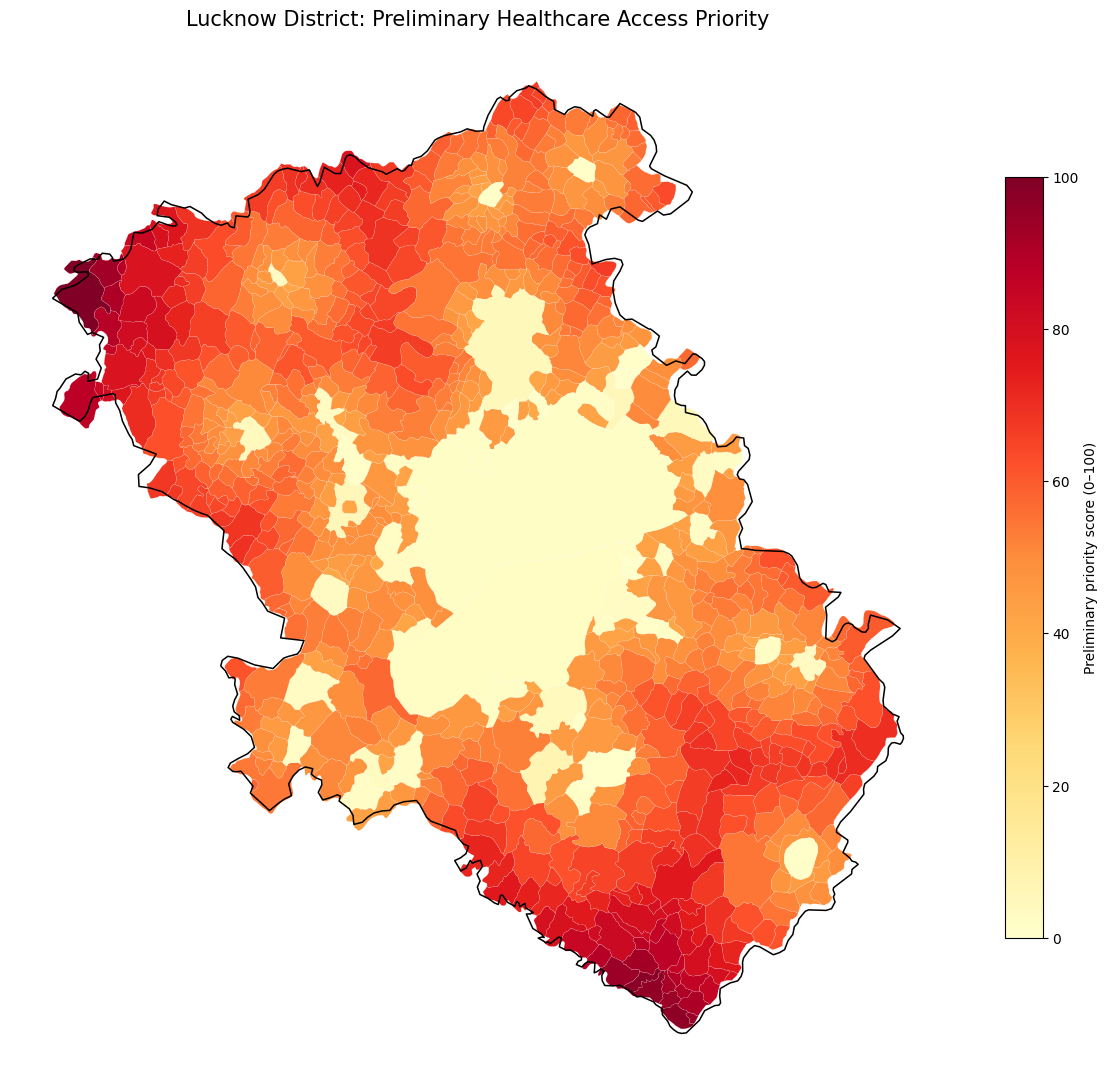

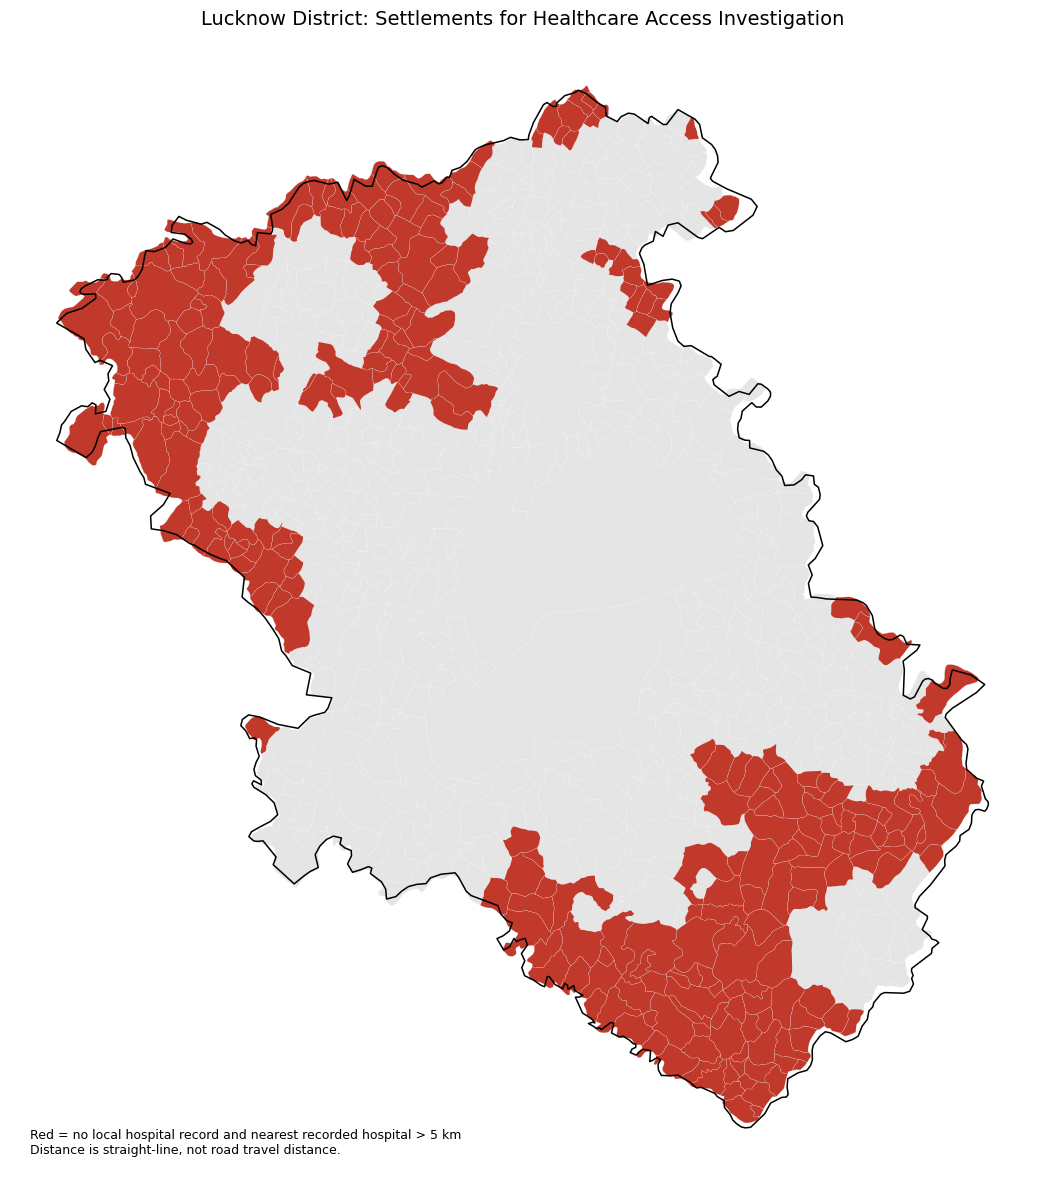


Saved outputs:
/content/gdrive/MyDrive/lucknow_census_processed/lucknow_settlement_priority_mapping.gpkg
/content/gdrive/MyDrive/lucknow_census_processed/lucknow_district_priority_score_map.png
/content/gdrive/MyDrive/lucknow_census_processed/lucknow_district_5km_investigation_map.png


In [ ]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

# Input files
gpkg_path = BASE_DIR / 'lucknow_district_analytical.gpkg'
priority_path = BASE_DIR / 'lucknow_settlement_priority_scores_v1.csv'
investigation_path = BASE_DIR / 'lucknow_priority_investigation_list_5km.csv'
district_path = BASE_DIR / 'lucknow_district_analytical.gpkg'

# Output files
output_gpkg = BASE_DIR / 'lucknow_settlement_priority_mapping.gpkg'
score_map_path = BASE_DIR / 'lucknow_district_priority_score_map.png'
screen_map_path = BASE_DIR / 'lucknow_district_5km_investigation_map.png'

# 1. Load settlement polygons and priority data
settlements = gpd.read_file(
    gpkg_path,
    layer='villages_towns_2011'
)

priority = pd.read_csv(priority_path)
investigation = pd.read_csv(investigation_path)

# Normalize join-key types
settlements['pc11_tv_id'] = settlements['pc11_tv_id'].astype(str).str.strip()
priority['pc11_tv_id'] = priority['pc11_tv_id'].astype(str).str.strip()
investigation['pc11_tv_id'] = investigation['pc11_tv_id'].astype(str).str.strip()

# Ensure each input has one row per settlement
assert settlements['pc11_tv_id'].is_unique, \
    "Settlement polygon IDs are not unique."
assert priority['pc11_tv_id'].is_unique, \
    "Priority dataset has duplicate settlement IDs."
assert investigation['pc11_tv_id'].is_unique, \
    "Investigation list has duplicate settlement IDs."

# 2. Join scores to polygons
map_gdf = settlements.merge(
    priority,
    on='pc11_tv_id',
    how='left',
    validate='one_to_one',
    suffixes=('', '_priority')
)

# Mark settlements in the 5 km investigation list
investigation_ids = set(investigation['pc11_tv_id'])
map_gdf['flagged_over_5km_no_local_hospital'] = (
    map_gdf['pc11_tv_id'].isin(investigation_ids)
)

print("Settlement polygons:", len(settlements))
print("Joined map rows:", len(map_gdf))
print("Polygons with priority scores:", map_gdf['priority_score_v1'].notna().sum())
print("5 km investigation settlements:",
      int(map_gdf['flagged_over_5km_no_local_hospital'].sum()))

assert len(map_gdf) == 819, "Unexpected settlement count after joining."
assert map_gdf['priority_score_v1'].notna().all(), \
    "Some settlement polygons did not receive a priority score."

# 3. Load district boundary for context
district = gpd.read_file(
    district_path,
    layer='district_boundary_2011'
)

if district.crs != map_gdf.crs:
    district = district.to_crs(map_gdf.crs)

# Use a projected CRS for plotting and consistent geometry handling
map_plot = map_gdf.to_crs(epsg=32644)
district_plot = district.to_crs(epsg=32644)

# 4. Map A: preliminary priority score
fig, ax = plt.subplots(figsize=(12, 12))

district_plot.boundary.plot(ax=ax, color='black', linewidth=1.1)

map_plot.plot(
    column='priority_score_v1',
    ax=ax,
    legend=True,
    cmap='YlOrRd',
    edgecolor='white',
    linewidth=0.08,
    legend_kwds={'label': 'Preliminary priority score (0–100)',
                 'shrink': 0.65}
)

ax.set_title(
    'Lucknow District: Preliminary Healthcare Access Priority',
    fontsize=15
)
ax.set_axis_off()
plt.tight_layout()
plt.savefig(score_map_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# 5. Map B: 5 km investigation screen
fig, ax = plt.subplots(figsize=(12, 12))

# Show all settlements in a neutral base layer
map_plot.plot(
    ax=ax,
    color='#E5E5E5',
    edgecolor='white',
    linewidth=0.08
)

# Highlight the 268 investigation settlements
flagged_plot = map_plot[
    map_plot['flagged_over_5km_no_local_hospital']
]

flagged_plot.plot(
    ax=ax,
    color='#C0392B',
    edgecolor='white',
    linewidth=0.12
)

district_plot.boundary.plot(ax=ax, color='black', linewidth=1.1)

ax.set_title(
    'Lucknow District: Settlements for Healthcare Access Investigation',
    fontsize=14
)
ax.text(
    0.02, 0.02,
    'Red = no local hospital record and nearest recorded hospital > 5 km\n'
    'Distance is straight-line, not road travel distance.',
    transform=ax.transAxes,
    fontsize=9,
    va='bottom'
)
ax.set_axis_off()
plt.tight_layout()
plt.savefig(screen_map_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# 6. Save joined mapping layer to a NEW GeoPackage
if output_gpkg.exists():
    output_gpkg.unlink()

map_gdf.to_file(
    output_gpkg,
    layer='settlement_priority',
    driver='GPKG'
)

print("\nSaved outputs:")
print(output_gpkg)
print(score_map_path)
print(screen_map_path)

In [ ]:
import geopandas as gpd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')
gpkg_path = BASE_DIR / 'lucknow_settlement_priority_mapping.gpkg'

gdf = gpd.read_file(
    gpkg_path,
    layer='settlement_priority'
)

print("Rows:", len(gdf))
print("\nAvailable columns:")
print(gdf.columns.tolist())

print("\nPriority score summary:")
print(gdf['priority_score_v1'].describe())

print("\nPriority tier counts:")
print(gdf['priority_tier_v1'].value_counts(dropna=False))

print("\nPopulation summary:")
print(gdf['pop2011_villagept'].describe())

Rows: 819

Available columns:
['pc11_s_id', 'pc11_d_id', 'pc11_sd_id', 'tehsil_name', 'pc11_tv_id', 'tv_name', 'tv_name_dir', 'is_town', 'pop2011_villagept', 'gp_code', 'gp_name', 'area_km2', 'tv_name_priority', 'tehsil_name_priority', 'is_town_priority', 'nearest_hospital_distance_km', 'nearest_hospital_record_key', 'nearest_hospital_name', 'nearest_hospital_ownership', 'nearest_hospital_beds', 'tv_name_indicator', 'tehsil_name_indicator', 'is_town_indicator', 'pop2011_villagept_priority', 'area_km2_priority', 'hospital_record_count', 'total_reported_beds', 'public_hospital_records', 'public_reported_beds', 'private_hospital_records', 'private_reported_beds', 'settlement_type', 'has_hospital_record_in_master', 'population_missing', 'area_missing', 'Primary Health Centre (Numbers)', 'Community Health Centre (Numbers)', 'Primary Heallth Sub Centre (Numbers)', 'Hospital Allopathic (Numbers)', 'town_population_from_census_csv', 'pop2011_villagept_original', 'village_population_from_census

In [ ]:
import geopandas as gpd
import pandas as pd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

input_path = BASE_DIR / 'lucknow_settlement_priority_mapping.gpkg'
output_path = BASE_DIR / 'lucknow_settlement_priority_mapping_popcorrected.gpkg'

gdf = gpd.read_file(
    input_path,
    layer='settlement_priority'
)

# Preserve the population value currently in the mapping layer
gdf['population_mapping_original'] = pd.to_numeric(
    gdf['pop2011_villagept'], errors='coerce'
)

# Create a corrected population field
gdf['population_corrected'] = gdf['population_mapping_original']

# Fill missing town population from the previously joined Census town field
if 'town_population_from_census_csv' in gdf.columns:
    town_pop = pd.to_numeric(
        gdf['town_population_from_census_csv'], errors='coerce'
    )
    gdf['population_corrected'] = gdf['population_corrected'].fillna(town_pop)

# Fill missing village population from the Census village field
if 'village_population_from_census_csv' in gdf.columns:
    village_pop = pd.to_numeric(
        gdf['village_population_from_census_csv'], errors='coerce'
    )
    gdf['population_corrected'] = gdf['population_corrected'].fillna(village_pop)

# Audit missing population after correction
missing_after = int(gdf['population_corrected'].isna().sum())
zero_population = int((gdf['population_corrected'] == 0).sum())

print("Settlement rows:", len(gdf))
print("Original missing population:", int(
    gdf['population_mapping_original'].isna().sum()
))
print("Missing population after correction:", missing_after)
print("Zero-population settlements:", zero_population)

print("\nPopulation totals by settlement type:")
print(
    gdf.groupby('settlement_type', dropna=False)['population_corrected']
       .agg(['count', 'sum'])
       .to_string()
)

# Calculate population exposure score only for positive populations.
# This is a descriptive score, not an estimate of unmet healthcare need.
valid_pop = gdf['population_corrected'].where(
    gdf['population_corrected'] > 0
)

gdf['population_exposure_score'] = (
    valid_pop.rank(pct=True) * 100
)

# Save a new derived GeoPackage
if output_path.exists():
    output_path.unlink()

gdf.to_file(
    output_path,
    layer='settlement_priority',
    driver='GPKG'
)

print("\nSaved:", output_path)

Settlement rows: 819
Original missing population: 11
Missing population after correction: 0
Zero-population settlements: 4

Population totals by settlement type:
                 count        sum
settlement_type                  
town                12  3038996.0
village            807  1550842.0

Saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_settlement_priority_mapping_popcorrected.gpkg


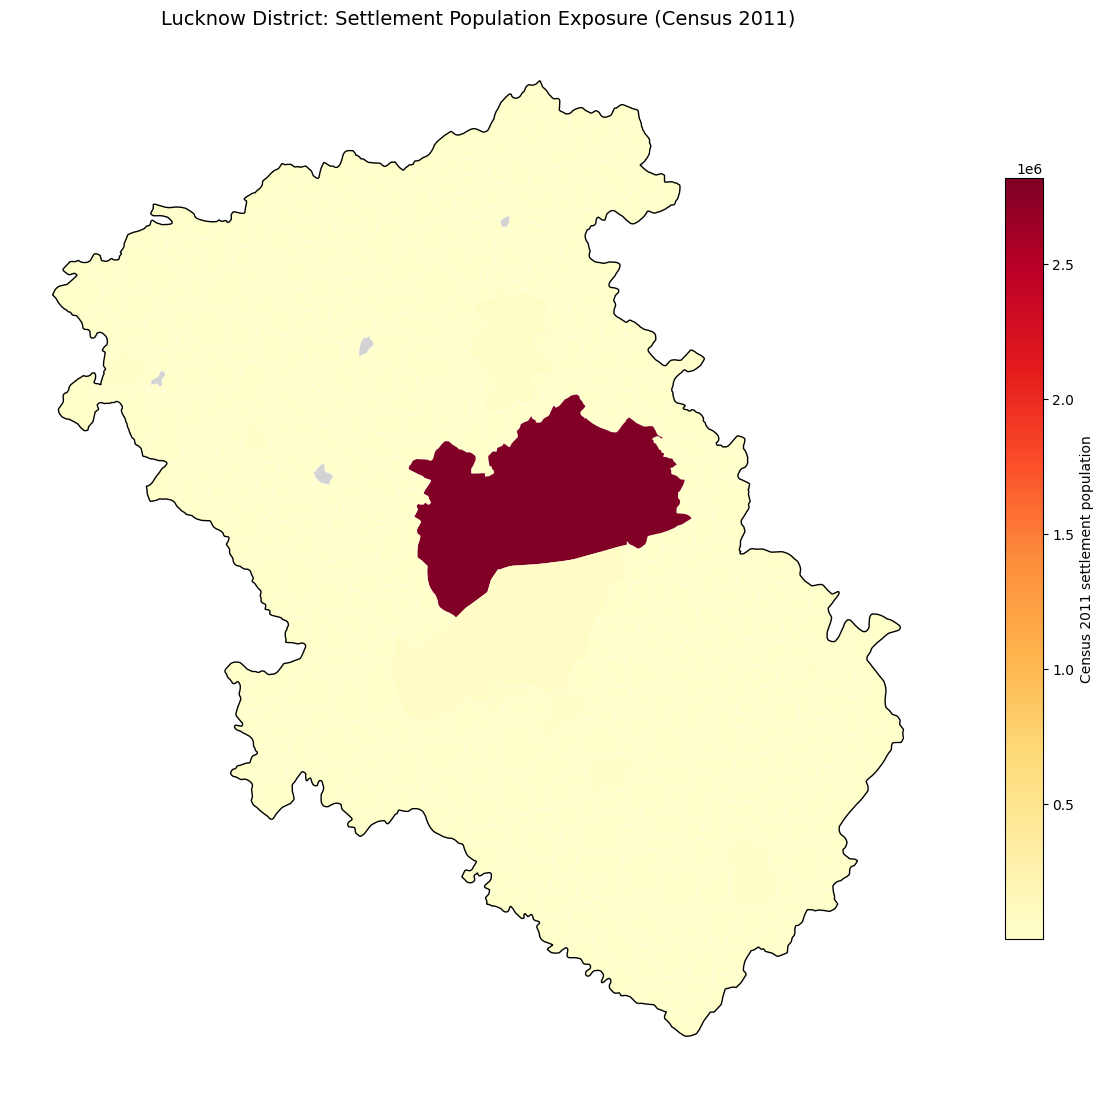

Map saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_district_population_exposure_map.png
Settlements mapped: 819
Positive-population settlements: 815
Zero-population settlements: 4


In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

input_path = BASE_DIR / 'lucknow_settlement_priority_mapping_popcorrected.gpkg'
output_path = BASE_DIR / 'lucknow_district_population_exposure_map.png'

gdf = gpd.read_file(
    input_path,
    layer='settlement_priority'
)

# Project to metres for map plotting
gdf_plot = gdf.to_crs(epsg=32644)

# Keep zero-population settlements visible but exclude them from population ranking
valid = gdf_plot['population_corrected'] > 0

fig, ax = plt.subplots(figsize=(12, 12))

gdf_plot.loc[valid].plot(
    column='population_corrected',
    ax=ax,
    cmap='YlOrRd',
    legend=True,
    edgecolor='white',
    linewidth=0.08,
    scheme=None,
    legend_kwds={
        'label': 'Census 2011 settlement population',
        'shrink': 0.65
    }
)

# Show the four zero-population settlements with a neutral fill
gdf_plot.loc[~valid].plot(
    ax=ax,
    color='lightgrey',
    edgecolor='white',
    linewidth=0.08
)

# Outline the overall district extent
gdf_plot.dissolve().boundary.plot(
    ax=ax,
    color='black',
    linewidth=1.0
)

ax.set_title(
    'Lucknow District: Settlement Population Exposure (Census 2011)',
    fontsize=14
)
ax.set_axis_off()
plt.tight_layout()
plt.savefig(output_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close()

print("Map saved:", output_path)
print("Settlements mapped:", len(gdf_plot))
print("Positive-population settlements:", int(valid.sum()))
print("Zero-population settlements:", int((~valid).sum()))

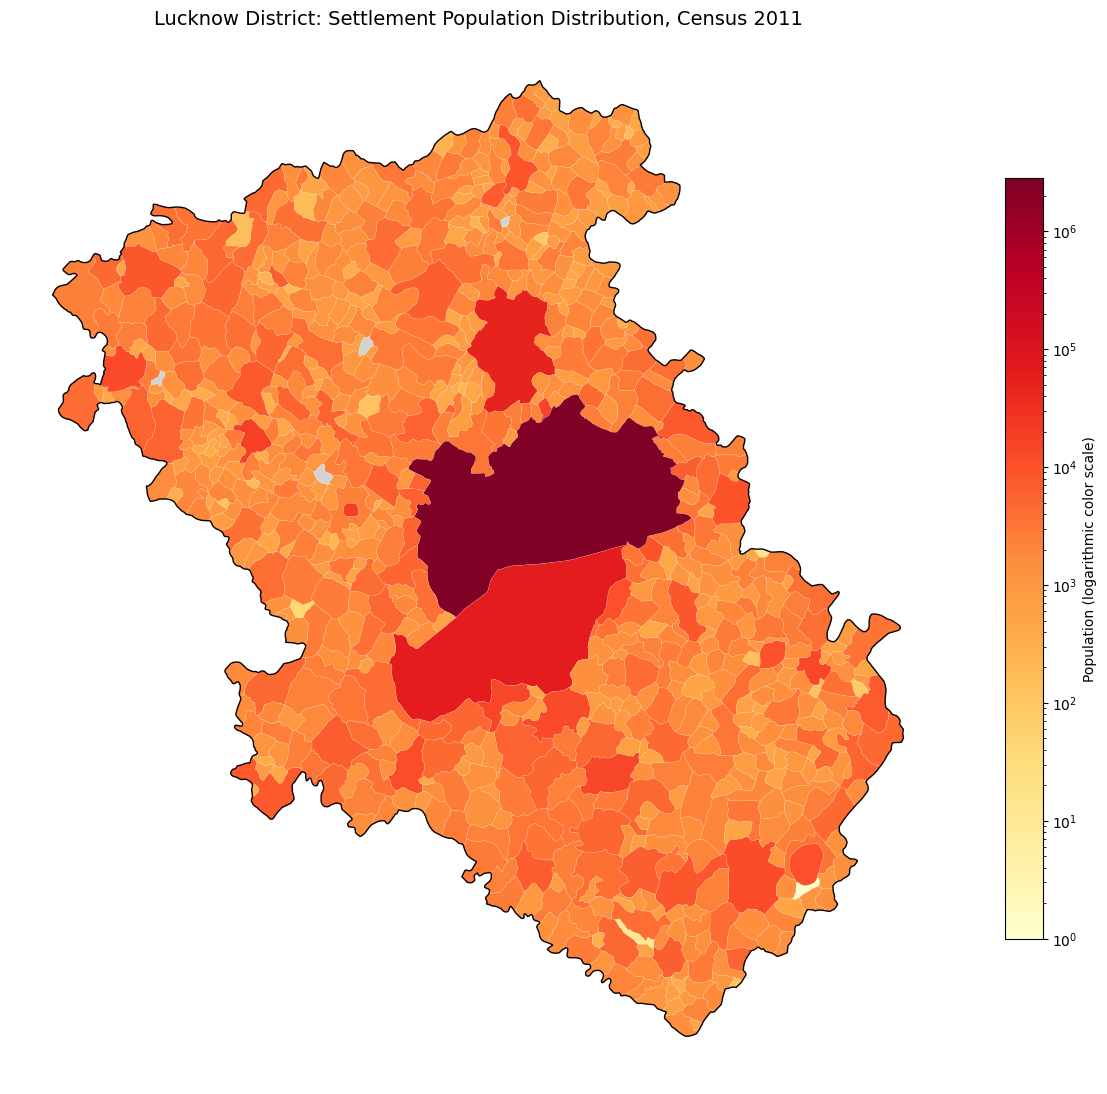

Saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_district_population_exposure_logscale.png


In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

input_path = BASE_DIR / 'lucknow_settlement_priority_mapping_popcorrected.gpkg'
output_path = BASE_DIR / 'lucknow_district_population_exposure_logscale.png'

gdf = gpd.read_file(
    input_path,
    layer='settlement_priority'
).to_crs(epsg=32644)

positive = gdf['population_corrected'] > 0

fig, ax = plt.subplots(figsize=(12, 12))

gdf.loc[positive].plot(
    column='population_corrected',
    ax=ax,
    cmap='YlOrRd',
    norm=LogNorm(
        vmin=1,
        vmax=gdf.loc[positive, 'population_corrected'].max()
    ),
    legend=True,
    edgecolor='white',
    linewidth=0.08,
    legend_kwds={
        'label': 'Population (logarithmic color scale)',
        'shrink': 0.65
    }
)

gdf.loc[~positive].plot(
    ax=ax,
    color='lightgrey',
    edgecolor='white',
    linewidth=0.08
)

gdf.dissolve().boundary.plot(
    ax=ax,
    color='black',
    linewidth=1
)

ax.set_title(
    'Lucknow District: Settlement Population Distribution, Census 2011',
    fontsize=14
)
ax.set_axis_off()

plt.tight_layout()
plt.savefig(output_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close()

print("Saved:", output_path)

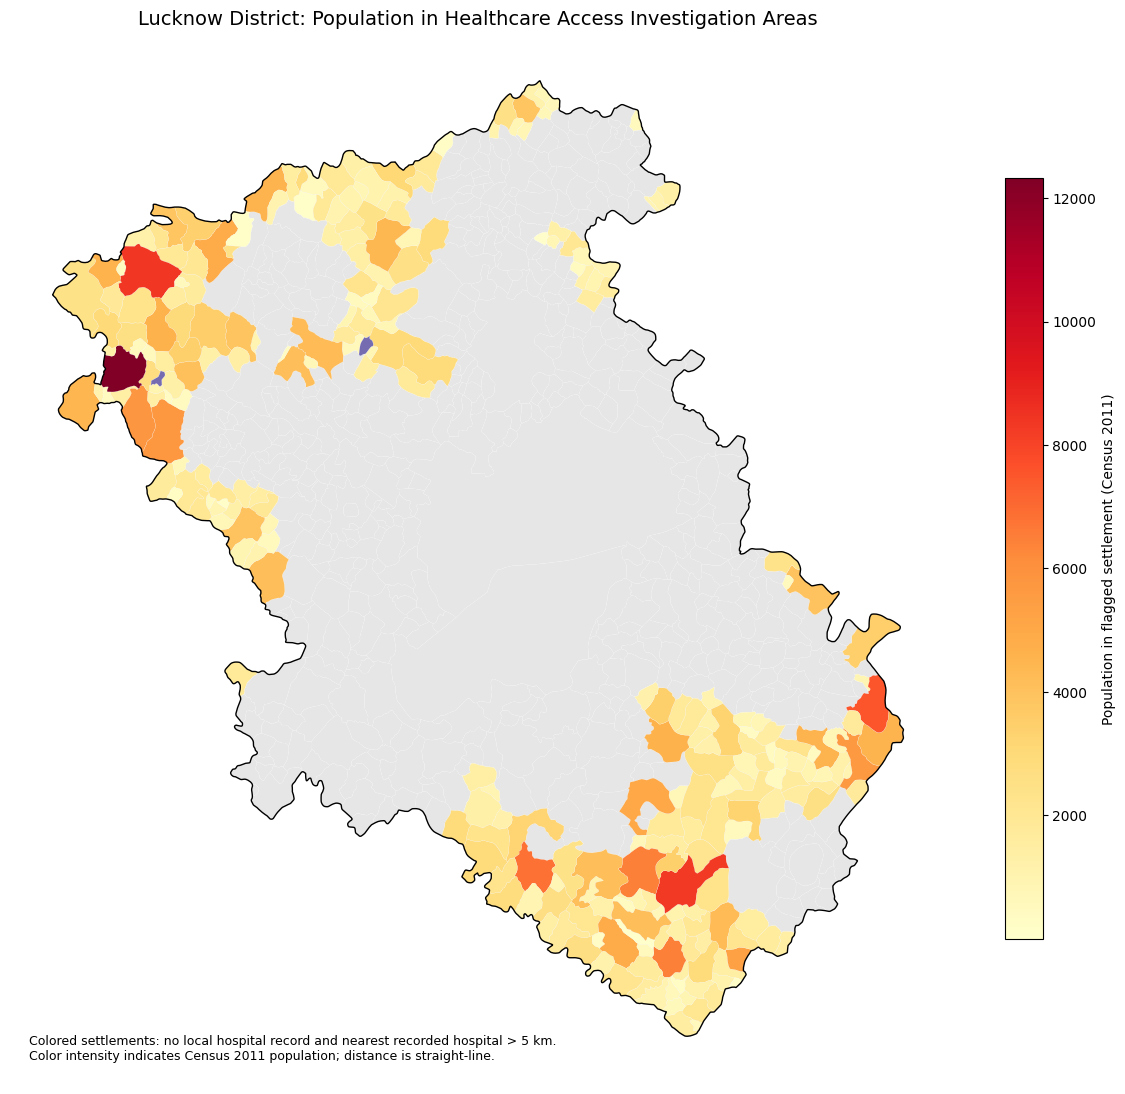

Flagged settlements: 268
Population in flagged settlements: 513304
Flagged settlements with positive population: 266
Flagged settlements with zero population: 2
Saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_district_flagged_population_exposure_map.png


In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

input_path = BASE_DIR / 'lucknow_settlement_priority_mapping_popcorrected.gpkg'
output_path = BASE_DIR / 'lucknow_district_flagged_population_exposure_map.png'

gdf = gpd.read_file(
    input_path,
    layer='settlement_priority'
).to_crs(epsg=32644)

# Identify settlements meeting both screening conditions
flagged = (
    gdf['hospital_record_count'].eq(0)
    & gdf['nearest_hospital_distance_km'].gt(5)
)

# Keep only positive population values for the color scale
flagged_positive = flagged & gdf['population_corrected'].gt(0)

fig, ax = plt.subplots(figsize=(12, 12))

# Context layer: all settlements
gdf.plot(
    ax=ax,
    color='#E6E6E6',
    edgecolor='white',
    linewidth=0.08
)

# Flagged settlements with positive population
gdf.loc[flagged_positive].plot(
    column='population_corrected',
    ax=ax,
    cmap='YlOrRd',
    norm=Normalize(
        vmin=1,
        vmax=gdf.loc[flagged_positive, 'population_corrected'].max()
    ),
    legend=True,
    edgecolor='white',
    linewidth=0.12,
    legend_kwds={
        'label': 'Population in flagged settlement (Census 2011)',
        'shrink': 0.65
    }
)

# Flagged settlements with zero population
flagged_zero = flagged & gdf['population_corrected'].eq(0)

if flagged_zero.any():
    gdf.loc[flagged_zero].plot(
        ax=ax,
        color='#756BB1',
        edgecolor='white',
        linewidth=0.12
    )

# District outline
gdf.dissolve().boundary.plot(
    ax=ax,
    color='black',
    linewidth=1
)

ax.set_title(
    'Lucknow District: Population in Healthcare Access Investigation Areas',
    fontsize=14
)

ax.text(
    0.02, 0.02,
    'Colored settlements: no local hospital record and nearest recorded hospital > 5 km.\n'
    'Color intensity indicates Census 2011 population; distance is straight-line.',
    transform=ax.transAxes,
    fontsize=9,
    va='bottom'
)

ax.set_axis_off()
plt.tight_layout()
plt.savefig(output_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close()

print("Flagged settlements:", int(flagged.sum()))
print(
    "Population in flagged settlements:",
    int(gdf.loc[flagged, 'population_corrected'].sum())
)
print("Flagged settlements with positive population:", int(flagged_positive.sum()))
print("Flagged settlements with zero population:", int(flagged_zero.sum()))
print("Saved:", output_path)

Hospital records loaded: 286
Missing latitude: 0
Missing longitude: 0

Ownership counts:
ownership
private    264
public      22
Name: count, dtype: int64


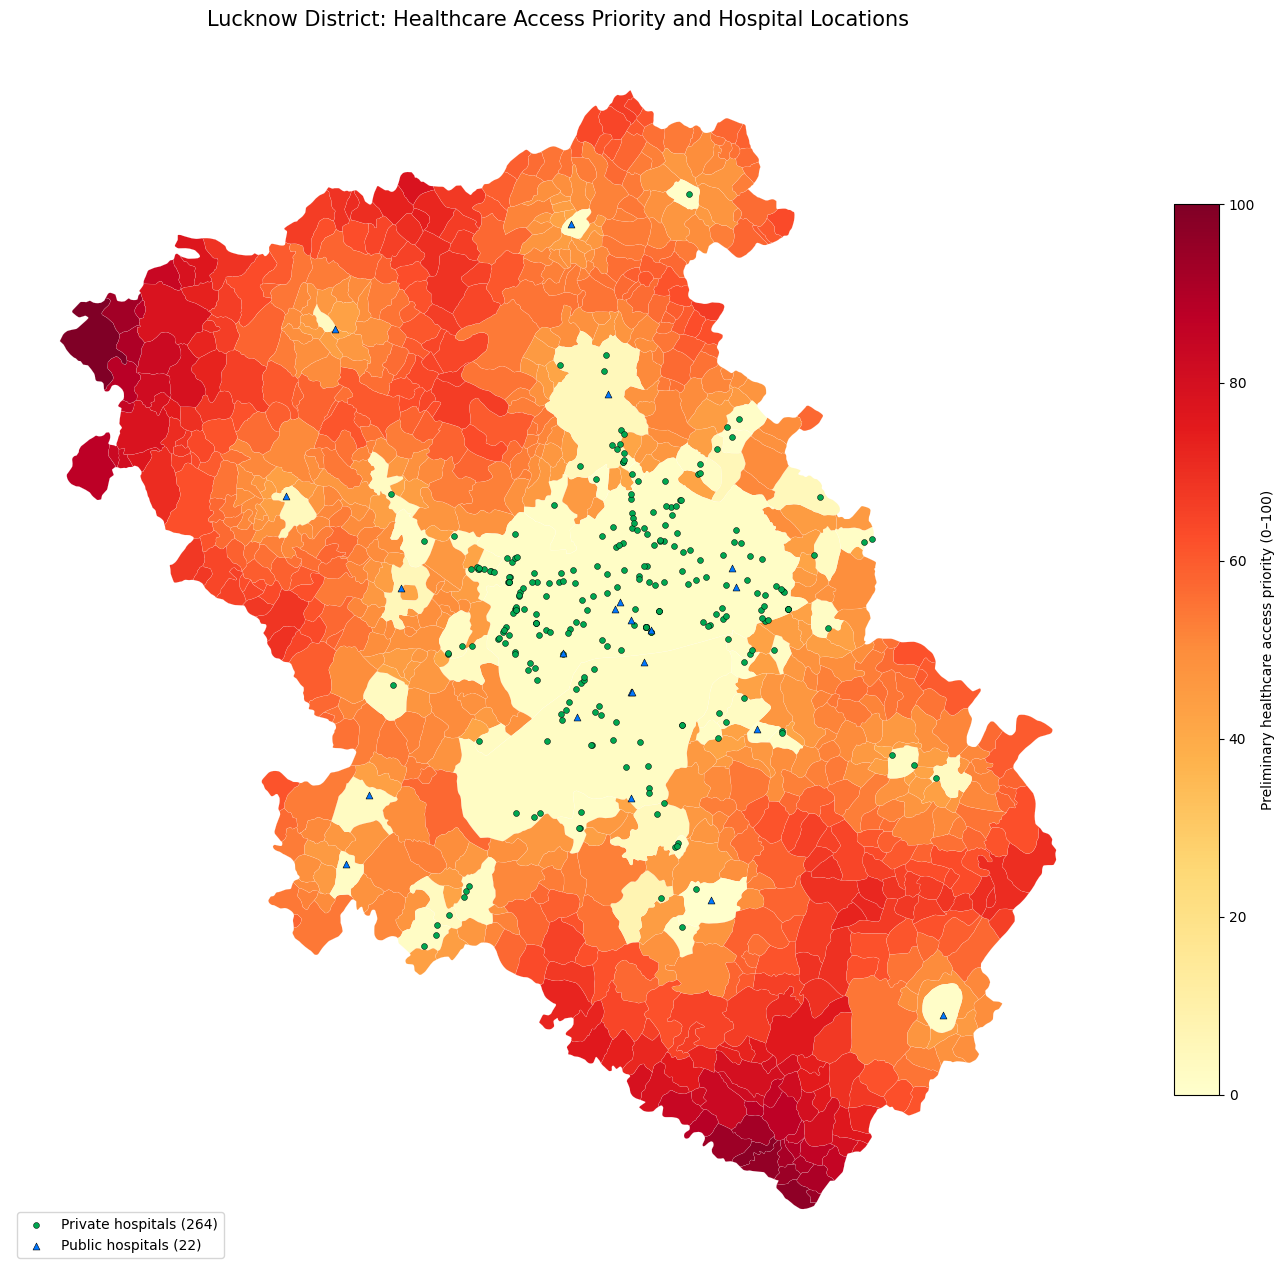


Total hospital records plotted: 286
Public records: 22
Private records: 264
Other/unknown ownership: 0
Saved map: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_priority_map_with_hospitals.png


In [ ]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

# Input files
map_path = BASE_DIR / 'lucknow_settlement_priority_mapping_popcorrected.gpkg'
hospital_path = BASE_DIR / 'lucknow_hospital_master_cleaned.csv'

# Output map
output_path = BASE_DIR / 'lucknow_priority_map_with_hospitals.png'

# 1. Load settlement priority polygons
settlements = gpd.read_file(
    map_path,
    layer='settlement_priority'
)

# 2. Load verified hospital master
hospitals = pd.read_csv(hospital_path)

print("Hospital records loaded:", len(hospitals))
print("Missing latitude:", hospitals['latitude'].isna().sum())
print("Missing longitude:", hospitals['longitude'].isna().sum())
print("\nOwnership counts:")
print(hospitals['ownership'].value_counts(dropna=False))

# 3. Convert hospital coordinates into spatial points
hospitals_gdf = gpd.GeoDataFrame(
    hospitals.copy(),
    geometry=gpd.points_from_xy(
        hospitals['longitude'],
        hospitals['latitude']
    ),
    crs='EPSG:4326'
)

# Project both layers for plotting
settlements_plot = settlements.to_crs(epsg=32644)
hospitals_plot = hospitals_gdf.to_crs(epsg=32644)

# 4. Plot priority polygons
fig, ax = plt.subplots(figsize=(14, 14))

settlements_plot.plot(
    column='priority_score_v1',
    ax=ax,
    cmap='YlOrRd',
    vmin=0,
    vmax=100,
    legend=True,
    edgecolor='white',
    linewidth=0.08,
    legend_kwds={
        'label': 'Preliminary healthcare access priority (0–100)',
        'shrink': 0.65
    }
)

# 5. Plot public and private hospitals separately
public = hospitals_plot[
    hospitals_plot['ownership'].astype(str).str.lower().str.strip()
    .eq('public')
]

private = hospitals_plot[
    hospitals_plot['ownership'].astype(str).str.lower().str.strip()
    .eq('private')
]

other = hospitals_plot[
    ~hospitals_plot.index.isin(public.index)
    & ~hospitals_plot.index.isin(private.index)
]

if not private.empty:
    private.plot(
        ax=ax,
        color='#00A650',
        marker='o',
        markersize=18,
        edgecolor='black',
        linewidth=0.35,
        label=f'Private hospitals ({len(private)})',
        zorder=5
    )

if not public.empty:
    public.plot(
        ax=ax,
        color='#0077FF',
        marker='^',
        markersize=25,
        edgecolor='black',
        linewidth=0.4,
        label=f'Public hospitals ({len(public)})',
        zorder=6
    )

if not other.empty:
    other.plot(
        ax=ax,
        color='black',
        marker='x',
        markersize=22,
        label=f'Other/unknown ownership ({len(other)})',
        zorder=7
    )

ax.set_title(
    'Lucknow District: Healthcare Access Priority and Hospital Locations',
    fontsize=15
)

ax.legend(loc='lower left', frameon=True)
ax.set_axis_off()

plt.tight_layout()
plt.savefig(output_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close()

print("\nTotal hospital records plotted:", len(hospitals_plot))
print("Public records:", len(public))
print("Private records:", len(private))
print("Other/unknown ownership:", len(other))
print("Saved map:", output_path)

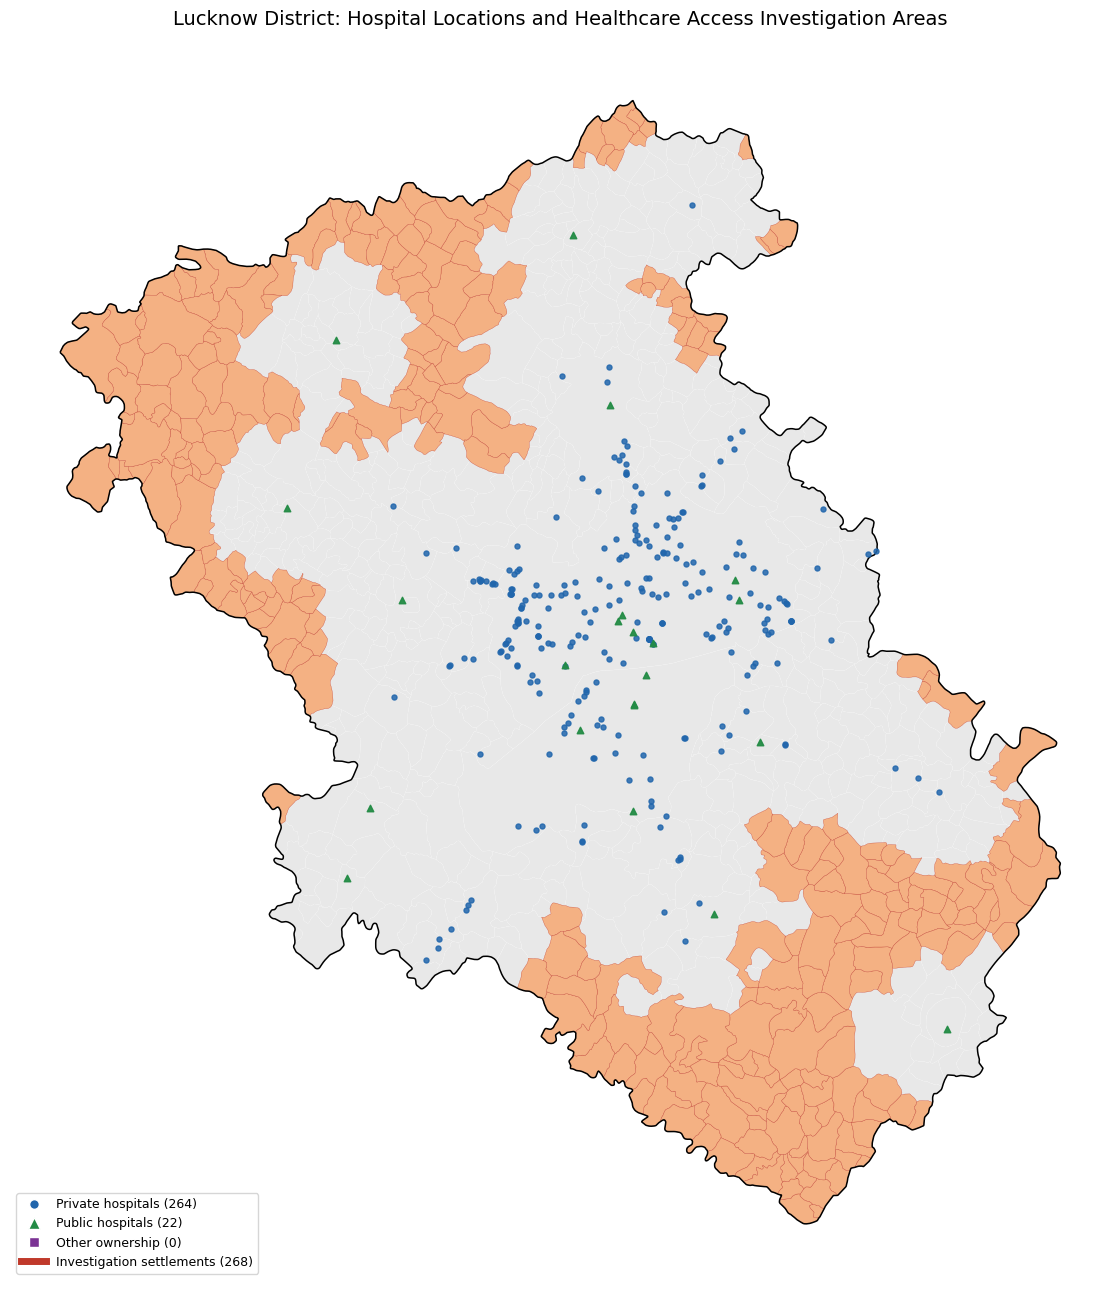

Settlement polygons: 819
Flagged investigation settlements: 268
Hospital records plotted: 286
Public hospital records: 22
Private hospital records: 264
Other ownership records: 0
Unique hospital coordinate pairs: 269
Map saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_district_hospitals_investigation_map.png


In [ ]:

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

# Input files
settlement_path = (
    BASE_DIR / 'lucknow_settlement_priority_mapping_popcorrected.gpkg'
)
hospital_path = BASE_DIR / 'lucknow_hospital_master_cleaned.csv'

# Output file: preserve all existing outputs
output_path = BASE_DIR / 'lucknow_district_hospitals_investigation_map.png'

# 1. Load settlement polygons
settlements = gpd.read_file(
    settlement_path,
    layer='settlement_priority'
)

# 2. Load the authoritative verified hospital master
hospitals = pd.read_csv(hospital_path)

required_columns = [
    'facility_name', 'ownership', 'latitude', 'longitude'
]
missing_columns = [
    c for c in required_columns if c not in hospitals.columns
]
if missing_columns:
    raise ValueError(f'Missing hospital columns: {missing_columns}')

# Preserve every hospital record, including shared coordinates
hospitals['latitude'] = pd.to_numeric(
    hospitals['latitude'], errors='coerce'
)
hospitals['longitude'] = pd.to_numeric(
    hospitals['longitude'], errors='coerce'
)

if hospitals[['latitude', 'longitude']].isna().any().any():
    raise ValueError('Hospital coordinates are missing in the master.')

# 3. Convert hospital coordinates to a GeoDataFrame
hospital_points = gpd.GeoDataFrame(
    hospitals.copy(),
    geometry=gpd.points_from_xy(
        hospitals['longitude'],
        hospitals['latitude']
    ),
    crs='EPSG:4326'
)

# Project both layers to metres
settlements = settlements.to_crs(epsg=32644)
hospital_points = hospital_points.to_crs(epsg=32644)

# 4. Identify settlements flagged by the 5 km investigation screen
flagged = settlements[
    settlements['flagged_over_5km_no_local_hospital'].fillna(False)
]

# 5. Separate public and private records for visualization
ownership = (
    hospital_points['ownership']
    .astype(str)
    .str.strip()
    .str.lower()
)

public_points = hospital_points[
    ownership.eq('public')
]
private_points = hospital_points[
    ownership.eq('private')
]
other_points = hospital_points[
    ~ownership.isin(['public', 'private'])
]

# 6. Plot the combined district map
fig, ax = plt.subplots(figsize=(14, 13))

# All settlements as the background
settlements.plot(
    ax=ax,
    color='#E8E8E8',
    edgecolor='white',
    linewidth=0.08,
    zorder=1
)

# Flagged settlements
flagged.plot(
    ax=ax,
    color='#F4B183',
    edgecolor='#C0392B',
    linewidth=0.22,
    zorder=2
)

# All hospital records: public and private displayed separately
private_points.plot(
    ax=ax,
    color='#2166AC',
    marker='o',
    markersize=13,
    alpha=0.85,
    zorder=4
)

public_points.plot(
    ax=ax,
    color='#238B45',
    marker='^',
    markersize=22,
    alpha=0.95,
    zorder=5
)

if len(other_points):
    other_points.plot(
        ax=ax,
        color='#7B3294',
        marker='s',
        markersize=18,
        zorder=6
    )

# District outline
settlements.dissolve().boundary.plot(
    ax=ax,
    color='black',
    linewidth=1.1,
    zorder=3
)

legend_items = [
    Line2D(
        [0], [0], marker='o', color='w',
        markerfacecolor='#2166AC', markersize=7,
        label=f'Private hospitals ({len(private_points)})'
    ),
    Line2D(
        [0], [0], marker='^', color='w',
        markerfacecolor='#238B45', markersize=8,
        label=f'Public hospitals ({len(public_points)})'
    ),
    Line2D(
        [0], [0], marker='s', color='w',
        markerfacecolor='#7B3294', markersize=7,
        label=f'Other ownership ({len(other_points)})'
    ),
    Line2D(
        [0], [0], color='#C0392B', linewidth=5,
        label=f'Investigation settlements ({len(flagged)})'
    )
]

ax.legend(
    handles=legend_items,
    loc='lower left',
    frameon=True,
    fontsize=9
)

ax.set_title(
    'Lucknow District: Hospital Locations and Healthcare Access '
    'Investigation Areas',
    fontsize=14,
    pad=14
)
ax.set_axis_off()

plt.tight_layout()
plt.savefig(output_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close()

print('Settlement polygons:', len(settlements))
print('Flagged investigation settlements:', len(flagged))
print('Hospital records plotted:', len(hospital_points))
print('Public hospital records:', len(public_points))
print('Private hospital records:', len(private_points))
print('Other ownership records:', len(other_points))
print('Unique hospital coordinate pairs:',
      hospital_points[['latitude', 'longitude']].drop_duplicates().shape[0])
print('Map saved:', output_path)


In [ ]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

input_path = (
    BASE_DIR / 'lucknow_settlement_priority_mapping_popcorrected.gpkg'
)
output_csv = BASE_DIR / 'lucknow_healthcare_dashboard_data.csv'

import geopandas as gpd

gdf = gpd.read_file(
    input_path,
    layer='settlement_priority'
)

# Dashboard fields, using only columns available in the current layer
candidate_columns = [
    'pc11_tv_id',
    'tv_name',
    'tehsil_name',
    'settlement_type',
    'is_town',
    'population_corrected',
    'area_km2',
    'hospital_record_count',
    'public_hospital_records',
    'private_hospital_records',
    'total_reported_beds',
    'public_reported_beds',
    'private_reported_beds',
    'nearest_hospital_distance_km',
    'nearest_hospital_name',
    'nearest_hospital_ownership',
    'nearest_hospital_beds',
    'beds_per_1000_population',
    'hospital_records_per_10000_population',
    'has_public_hospital_record',
    'has_private_hospital_record',
    'priority_score_v1',
    'priority_rank_v1',
    'priority_tier_v1',
    'flagged_over_5km_no_local_hospital',
    'Primary Health Centre (Numbers)',
    'Community Health Centre (Numbers)',
    'Primary Heallth Sub Centre (Numbers)',
    'Hospital Allopathic (Numbers)',
    'census_healthcare_missing_count',
    'population_zero_flag',
    'small_population_rate_caution'
]

columns = [c for c in candidate_columns if c in gdf.columns]
dashboard = gdf[columns].copy()

# Standardize a few field names for easier dashboard use
dashboard = dashboard.rename(columns={
    'pc11_tv_id': 'settlement_code',
    'tv_name': 'settlement_name',
    'tehsil_name': 'tehsil',
    'population_corrected': 'population_2011',
    'nearest_hospital_distance_km': 'nearest_hospital_distance_km',
    'priority_score_v1': 'priority_score',
    'priority_rank_v1': 'priority_rank',
    'priority_tier_v1': 'priority_tier',
    'flagged_over_5km_no_local_hospital': 'investigation_flag_5km'
})

dashboard['investigation_flag_5km'] = (
    dashboard['investigation_flag_5km'].fillna(False).astype(bool)
)

# Validate row and key counts
assert len(dashboard) == 819
assert dashboard['settlement_code'].nunique() == 819
assert dashboard['population_2011'].notna().all()

dashboard.to_csv(output_csv, index=False)

print("Dashboard rows:", len(dashboard))
print("Unique settlement codes:", dashboard['settlement_code'].nunique())
print("Total population:", int(dashboard['population_2011'].sum()))
print("Flagged settlements:", int(dashboard['investigation_flag_5km'].sum()))

print("\nPriority tiers:")
print(dashboard['priority_tier'].value_counts(dropna=False).to_string())

print("\nTehsil coverage:")
print(dashboard.groupby('tehsil')['settlement_code'].nunique().to_string())

print("\nSaved:", output_csv)

Dashboard rows: 819
Unique settlement codes: 819
Total population: 4589838
Flagged settlements: 268

Priority tiers:
priority_tier
High preliminary priority         470
Moderate preliminary priority     239
Very high preliminary priority     58
Lower preliminary priority         52

Tehsil coverage:
tehsil
Bakshi Ka Talab    189
Lucknow (Sadar)    210
Malihabad          188
Mohanlalganj       232

Saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_healthcare_dashboard_data.csv


In [ ]:

# Install any missing dashboard libraries
%pip -q install folium ipywidgets

import pandas as pd
import geopandas as gpd
import folium
import ipywidgets as widgets

from pathlib import Path
from IPython.display import display, clear_output, HTML

BASE_DIR = Path('/content/gdrive/MyDrive/lucknow_census_processed')

CSV_PATH = BASE_DIR / 'lucknow_healthcare_dashboard_data.csv'
GPKG_PATH = BASE_DIR / 'lucknow_settlement_priority_mapping_popcorrected.gpkg'
HOSPITAL_PATH = BASE_DIR / 'lucknow_hospital_master_cleaned.csv'

# --------------------------------------------------
# 1. Load dashboard data and geometry
# --------------------------------------------------
df = pd.read_csv(CSV_PATH)
geo = gpd.read_file(GPKG_PATH, layer='settlement_priority')
hospitals = pd.read_csv(HOSPITAL_PATH)

df['settlement_code'] = df['settlement_code'].astype(str).str.strip()
geo['pc11_tv_id'] = geo['pc11_tv_id'].astype(str).str.strip()

# Use the exact settlement code to attach geometry
geo = geo.merge(
    df,
    left_on='pc11_tv_id',
    right_on='settlement_code',
    how='left',
    validate='one_to_one',
    suffixes=('', '_dashboard')
)

geo = geo.to_crs(epsg=4326)

# Convert important numeric fields safely
numeric_cols = [
    'population_2011',
    'hospital_record_count',
    'total_reported_beds',
    'nearest_hospital_distance_km',
    'priority_score'
]

for col in numeric_cols:
    if col in geo.columns:
        geo[col] = pd.to_numeric(geo[col], errors='coerce')

geo['investigation_flag_5km'] = (
    geo['investigation_flag_5km']
    .astype(str).str.lower().isin(['true', '1', 'yes'])
)

hospitals['latitude'] = pd.to_numeric(
    hospitals['latitude'], errors='coerce'
)
hospitals['longitude'] = pd.to_numeric(
    hospitals['longitude'], errors='coerce'
)

print("Loaded settlements:", len(df))
print("Loaded settlement geometries:", len(geo))
print("Loaded hospital records:", len(hospitals))

assert len(df) == 819
assert len(geo) == 819

# --------------------------------------------------
# 2. Create interactive filters
# --------------------------------------------------
tehsil_options = ['All tehsils'] + sorted(
    df['tehsil'].dropna().unique().tolist()
)

type_options = ['All types'] + sorted(
    df['settlement_type'].dropna().astype(str).unique().tolist()
)

tier_options = ['All tiers'] + sorted(
    df['priority_tier'].dropna().unique().tolist()
)

tehsil_filter = widgets.Dropdown(
    options=tehsil_options,
    value='All tehsils',
    description='Tehsil:',
    layout=widgets.Layout(width='360px')
)

type_filter = widgets.Dropdown(
    options=type_options,
    value='All types',
    description='Settlement:',
    layout=widgets.Layout(width='360px')
)

tier_filter = widgets.Dropdown(
    options=tier_options,
    value='All tiers',
    description='Priority:',
    layout=widgets.Layout(width='500px')
)

investigation_filter = widgets.Dropdown(
    options=[
        ('All settlements', 'all'),
        ('Investigation flags only', 'flagged'),
        ('Not flagged', 'not_flagged')
    ],
    value='all',
    description='Access screen:',
    layout=widgets.Layout(width='360px')
)

output = widgets.Output()

# --------------------------------------------------
# 3. Dashboard update function
# --------------------------------------------------
def update_dashboard(change=None):
    with output:
        clear_output(wait=True)

        selected = geo.copy()

        if tehsil_filter.value != 'All tehsils':
            selected = selected[
                selected['tehsil'] == tehsil_filter.value
            ]

        if type_filter.value != 'All types':
            selected = selected[
                selected['settlement_type'].astype(str)
                == type_filter.value
            ]

        if tier_filter.value != 'All tiers':
            selected = selected[
                selected['priority_tier'] == tier_filter.value
            ]

        if investigation_filter.value == 'flagged':
            selected = selected[
                selected['investigation_flag_5km']
            ]
        elif investigation_filter.value == 'not_flagged':
            selected = selected[
                ~selected['investigation_flag_5km']
            ]

        # Summary metrics for the filtered settlements
        population = selected['population_2011'].sum()
        hospital_records = selected['hospital_record_count'].sum()
        beds = selected['total_reported_beds'].sum()
        flagged_count = int(
            selected['investigation_flag_5km'].sum()
        )

        public_records = selected['public_hospital_records'].sum()
        private_records = selected['private_hospital_records'].sum()

        print("HEALTHCARE ACCESS DASHBOARD")
        print("=" * 42)
        print(f"Settlements selected: {len(selected):,}")
        print(f"Census 2011 population: {population:,.0f}")
        print(f"Flagged settlements: {flagged_count:,}")
        print(f"Hospital records in selected settlements: {hospital_records:,.0f}")
        print(f"Reported beds in selected settlements: {beds:,.0f}")
        print(f"Local public hospital records: {public_records:,.0f}")
        print(f"Local private hospital records: {private_records:,.0f}")

        if len(selected) == 0:
            print("\nNo settlements match the selected filters.")
            return

        # Map center
        center = selected.geometry.union_all().centroid
        m = folium.Map(
            location=[center.y, center.x],
            zoom_start=9,
            tiles='CartoDB positron'
        )

        # Full district settlement context
        folium.GeoJson(
            geo[['pc11_tv_id', 'geometry']].to_json(),
            name='All settlement boundaries',
            style_function=lambda feature: {
                'fillColor': '#E5E5E5',
                'color': '#FFFFFF',
                'weight': 0.25,
                'fillOpacity': 0.25
            },
            show=True
        ).add_to(m)

        # Color the selected settlements by priority tier
        tier_colors = {
            'Lower preliminary priority': '#74C476',
            'Moderate preliminary priority': '#FEE08B',
            'High preliminary priority': '#FC8D59',
            'Very high preliminary priority': '#B2182B'
        }

        def style_selected(feature):
            tier = feature['properties'].get('priority_tier')
            flagged = str(
                feature['properties'].get('investigation_flag_5km', '')
            ).lower() in ['true', '1']

            return {
                'fillColor': '#C0392B' if flagged else tier_colors.get(
                    tier, '#808080'
                ),
                'color': '#555555',
                'weight': 0.6,
                'fillOpacity': 0.72
            }

        # Prepare compact popup attributes
        popup_fields = [
            'settlement_name',
            'tehsil',
            'settlement_type',
            'population_2011',
            'hospital_record_count',
            'nearest_hospital_distance_km',
            'nearest_hospital_name',
            'priority_score',
            'priority_tier',
            'investigation_flag_5km'
        ]

        popup_fields = [
            c for c in popup_fields if c in selected.columns
        ]

        selected_map = selected.copy()

        # Remove any duplicate column names before GeoJSON conversion
        selected_map = selected_map.loc[
            :, ~selected_map.columns.duplicated()
        ]

        folium.GeoJson(
            selected_map[popup_fields + ['geometry']].to_json(),
            name='Filtered settlements',
            style_function=style_selected,
            tooltip=folium.GeoJsonTooltip(
                fields=[
                    c for c in [
                        'settlement_name',
                        'tehsil',
                        'priority_tier'
                    ] if c in selected_map.columns
                ],
                aliases=['Settlement:', 'Tehsil:', 'Priority:']
            ),
            popup=folium.GeoJsonPopup(
                fields=popup_fields,
                aliases=[
                    c.replace('_', ' ').title()
                    for c in popup_fields
                ],
                localize=True,
                max_width=350
            )
        ).add_to(m)

        # Add hospital markers; coordinates and records are preserved
        ownership = (
            hospitals['ownership'].astype(str).str.lower().str.strip()
        )

        public_h = hospitals[ownership.eq('public')]
        private_h = hospitals[ownership.eq('private')]

        for subset, color, icon_name, label in [
            (public_h, 'green', 'plus-sign', 'Public'),
            (private_h, 'blue', 'info-sign', 'Private')
        ]:
            layer = folium.FeatureGroup(
                name=f'{label} hospitals ({len(subset)})',
                show=True
            )

            for _, h in subset.iterrows():
                if pd.isna(h['latitude']) or pd.isna(h['longitude']):
                    continue

                name = str(h.get('facility_name', 'Unnamed facility'))
                beds_value = h.get('beds', None)

                popup_text = (
                    f"<b>{name}</b><br>"
                    f"Ownership: {label}<br>"
                    f"Reported beds: {beds_value}"
                )

                folium.Marker(
                    location=[h['latitude'], h['longitude']],
                    tooltip=name,
                    popup=folium.Popup(popup_text, max_width=300),
                    icon=folium.Icon(
                        color=color,
                        icon=icon_name
                    )
                ).add_to(layer)

            layer.add_to(m)

        folium.LayerControl(collapsed=False).add_to(m)

        display(HTML(
            "<p><b>Map legend:</b> Red = flagged for investigation; "
            "other colors = priority tier. Hospital markers distinguish "
            "public and private facilities.</p>"
        ))
        display(m)

# Update dashboard when any filter changes
for control in [
    tehsil_filter,
    type_filter,
    tier_filter,
    investigation_filter
]:
    control.observe(update_dashboard, names='value')

display(widgets.VBox([
    widgets.HTML("<h3>Lucknow Healthcare Accessibility Dashboard</h3>"),
    tehsil_filter,
    type_filter,
    tier_filter,
    investigation_filter,
    output
]))

update_dashboard()
